<div style="background: linear-gradient(135deg, #003366 0%, #0055a5 100%); border-radius: 12px; padding: 18px 26px; display: flex; align-items: center; gap: 24px; box-shadow: 0 4px 12px rgba(0,0,0,0.2);">
    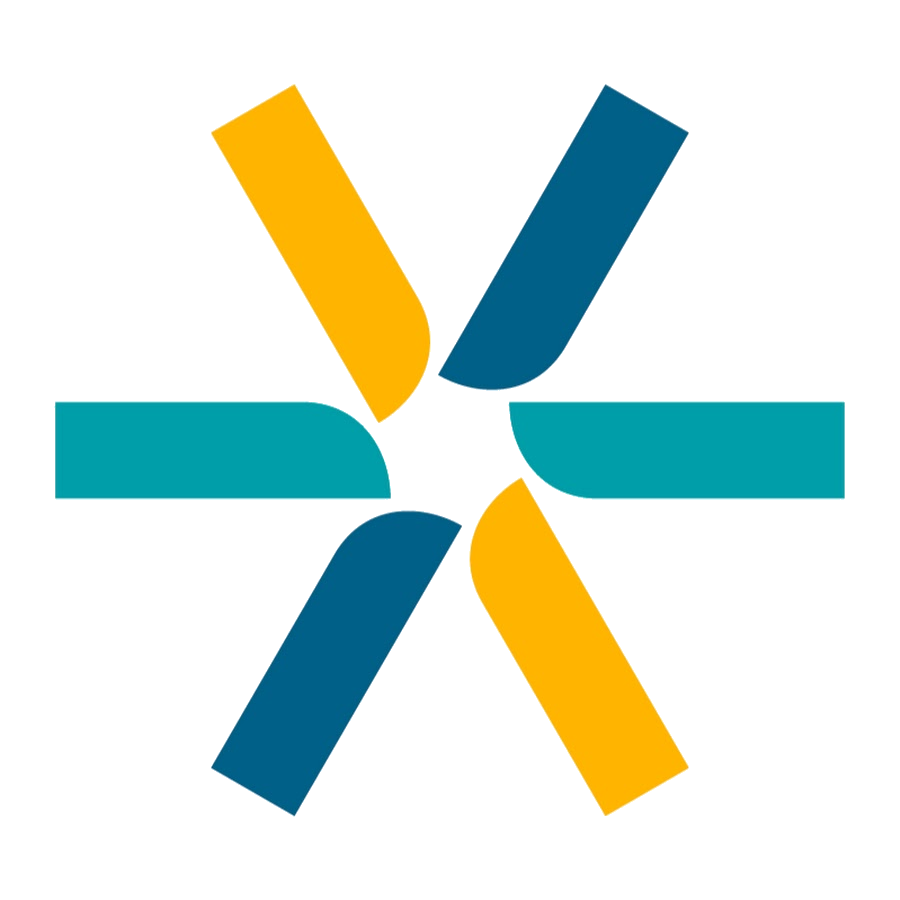
    <div>
        <h1 style="margin: 0; color: #ffffff; font-size: 1.45em; letter-spacing: 0.5px;">Aprendizaje Automático y Grandes Datos</h1>
        <h2 style="margin: 6px 0 2px 0; color: #cce4ff; font-size: 1.15em; font-weight: normal;">Ensambles: fundamentos y métodos por promediado · demanda eléctrica (CAMMESA)</h2>
        <h3 style="margin: 0 0 8px 0; color: #a8d0f5; font-size: 1em; font-weight: normal;">Unidad 7 · Votar, remuestrear, bosques</h3>
        <span style="background: #ffd700; color: #003366; font-weight: bold; font-size: 0.9em; padding: 3px 12px; border-radius: 20px;">⚡ Grupo 6 · Clase 38 sobre nuestro dataset</span>
    </div>
</div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Antes de empezar</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">La pregunta</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">La misma de la unidad 6: ¿la demanda de este agente va a caer más de un 15 % el mes que viene, y con qué probabilidad? Pero cambia la estrategia: en vez de buscar el mejor modelo, se entrenan muchos y se agregan sus predicciones.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Los datos</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Las mismas filas, las mismas ocho predictoras, el mismo corte temporal y la misma prueba. Las referencias son los tres modelos de la unidad 6: la logística (AUC ~0,66), los vecinos con k = 101 (~0,74) y el árbol de profundidad 10 con mínimo 200 por hoja (~0,72).</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se quiere resolver</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Por qué muchos modelos flojos juntos le ganan a uno bueno, y con qué condiciones (suficientes y diversos). Y las tres formas de conseguir diversidad: modelos distintos que votan; el mismo modelo sobre muestras distintas (bagging, pasting, fuera de la bolsa, parches); y árboles con filas y atributos al azar (bosques, extra-árboles), con sus dos importancias.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se muestra</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Las mismas secciones de la clase 38: 1 · datos y referencias → A · la multitud → B · votar → C · remuestrear → D · bosques → E · comparativo → F · usarlo, con los votos de los árboles.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Cómo se decide</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Sobre la prueba, con las seis métricas, contra las tres referencias. Lo que hay que elegir (el mínimo por hoja del bosque) se elige con validación cruzada temporal, no con lo que queda fuera de la bolsa; la sección C explica por qué.</td></tr></table></div>

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué hay que saber antes de modelar</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>El umbral del 50 % no sirve acá.</b> Con 17 % de caídas y señales débiles, ningún modelo de la unidad 6 le da más de 0,5 a casi ninguna fila: con 0,5 todos dicen «no cae» siempre, y se «equivocan en el mismo lugar» por construcción. Para mirar decisiones (la votación rígida, dónde se equivoca cada uno, la varianza) se usa el umbral de 0,15 que la clase 32 eligió en validación. Para el AUC y el log-loss no hace falta umbral.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Muchas filas, y el tiempo.</b> 31 000 filas: un bosque de 500 árboles sin freno guarda millones de nodos y tarda. El cuaderno usa 500 donde importa y menos (100 o 200) en los experimentos repetidos; D.3 muestra que con 100 ya se estabiliza. Corrido en una máquina de un solo núcleo tarda varios minutos; con varios, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">n_jobs=-1</code> lo reparte.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Los árboles sin freno no son lo mejor acá,</b> a diferencia de la cátedra. Con un objetivo tan ruidoso, cada árbol sin freno memoriza ruido; el promedio lo suaviza, pero un mínimo por hoja moderado ayuda. Se muestra y se elige con validación.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">1 · Los datos, y las tres referencias</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Lo mismo que las clases anteriores, en una celda</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Cargar, armar las predictoras, partir por fecha, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">registrar()</code>, y los tres modelos de la unidad 6 como referencia. Los árboles y los bosques aceptan faltantes; la logística y los vecinos llevan el imputador.</p></div>

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import cross_val_score, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss

AZUL, AMBAR, GRIS, ROJO, VERDE = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57"
pd.set_option("display.width", 130)
np.set_printoptions(suppress=True, precision=3)
warnings.filterwarnings("ignore", message="Skipping features without any observed values")
warnings.filterwarnings("ignore", message="Some inputs do not have OOB scores")   # primeros pliegues temporales sin var_hace_un_anio

CANDIDATAS = [Path("datos/demanda-ltimos-aos.csv"), Path("demanda-ltimos-aos.csv"), Path("../datos/demanda-ltimos-aos.csv"), Path("../Regresion/datos/demanda-ltimos-aos.csv")]
RUTA = next((p for p in CANDIDATAS if p.exists()), None)
if RUTA is None:
    raise FileNotFoundError(f"No encontré el CSV. Ponelo en alguna de estas rutas: {[str(p) for p in CANDIDATAS]}")
demanda = pd.read_csv(RUTA, encoding="utf-8-sig", dtype={"indice_tiempo": str})
demanda["periodo"] = pd.PeriodIndex(demanda["indice_tiempo"], freq="M")
demanda["serie"] = demanda["agente_nemo"] + " | " + demanda["tarifa"]
base_lags = demanda[["serie", "periodo", "demanda_MWh"]]
for k in [1, 2, 12, 13]:
    t = base_lags.copy(); t["periodo"] = t["periodo"] + k
    demanda = demanda.merge(t.rename(columns={"demanda_MWh": f"lag{k}"}), on=["serie", "periodo"], how="left")

datos = demanda[demanda["lag1"] > 0].copy()
datos["ratio_dias"] = datos["periodo"].dt.days_in_month / (datos["periodo"] - 1).dt.days_in_month
datos["var_mes_ant"] = pd.Series(np.where(datos["lag2"] > 0, datos["lag1"] / datos["lag2"] - 1, np.nan), index=datos.index).clip(-1, 3)
datos["volatilidad"] = datos["var_mes_ant"].abs()
datos["var_hace_un_anio"] = pd.Series(np.where((datos["lag13"] > 0) & (datos["lag12"] >= 0), datos["lag12"] / datos["lag13"] - 1, np.nan), index=datos.index).clip(-1, 3)
datos["log_tamano"] = np.log10(datos["lag1"])
datos["mes_num"] = datos["periodo"].dt.month
datos["es_gran_usuario"] = (datos["categoria_demanda"] == "Gran Usuario").astype(int)
datos["es_residencial"] = (datos["categoria_tarifa"] == "Residencial").astype(int)
UMBRAL_CAIDA = 0.15
datos["cae_fuerte"] = (datos["demanda_MWh"] < (1 - UMBRAL_CAIDA) * datos["lag1"]).astype(int)
datos = datos.sort_values(["periodo", "serie"]).reset_index(drop=True)

PREDICTORAS = ["ratio_dias", "var_mes_ant", "volatilidad", "var_hace_un_anio", "log_tamano", "mes_num", "es_gran_usuario", "es_residencial"]
OBJETIVO = "cae_fuerte"
CORTE = pd.Period("2019-06", freq="M")
ent_mask = datos["periodo"] <= CORTE
X_ent, X_pru = datos.loc[ent_mask, PREDICTORAS], datos.loc[~ent_mask, PREDICTORAS]
y_ent, y_pru = datos.loc[ent_mask, OBJETIVO], datos.loc[~ent_mask, OBJETIVO]
CV = TimeSeriesSplit(n_splits=5)

def preparado(modelo):
    """Imputar, escalar y recién entonces el modelo."""
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), modelo)

resultados = {}
def guardar(nombre, prob, t_fit, t_pred, modelo, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    resultados[nombre] = {"exactitud": accuracy_score(y_pru, pred), "precisión": precision_score(y_pru, pred, zero_division=0),
                          "exhaustividad": recall_score(y_pru, pred), "F1": f1_score(y_pru, pred), "AUC": roc_auc_score(y_pru, prob),
                          "log-loss": log_loss(y_pru, prob), "ajuste (ms)": t_fit, "predicción (ms)": t_pred, "modelo": modelo}

def registrar(nombre, modelo, umbral=0.5, cols=None):
    cols = PREDICTORAS if cols is None else cols
    t0 = time.perf_counter(); modelo.fit(X_ent[cols], y_ent); t_fit = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter(); prob = modelo.predict_proba(X_pru[cols])[:, 1]; t_pred = (time.perf_counter() - t0) * 1000
    guardar(nombre, prob, t_fit, t_pred, modelo, umbral)
    return modelo

registrar("línea de base (mayoritaria)", DummyClassifier(strategy="most_frequent"))
logistica = registrar("regresión logística (clase 32)", preparado(LogisticRegression()))
vecinos = registrar("k vecinos, k=101 (clase 34)", preparado(KNeighborsClassifier(n_neighbors=101)))
arbol = registrar("árbol, profundidad 10, mínimo 200 (clase 35)", DecisionTreeClassifier(max_depth=10, min_samples_leaf=200, random_state=2026))
UMBRAL_ALT = 0.15                                           # el umbral elegido en validación en la clase 32
print(f"{len(X_ent)} filas de entrenamiento ({y_ent.mean() * 100:.1f} % caídas) · {len(X_pru)} de prueba ({y_pru.sum()} caídas)")
for k in list(resultados)[1:]:
    r = resultados[k]; print(f"Referencia · {k:44s} AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f}")

31415 filas de entrenamiento (17.1 % caídas) · 5982 de prueba (759 caídas)
Referencia · regresión logística (clase 32)               AUC 0.663 · log-loss 0.365
Referencia · k vecinos, k=101 (clase 34)                  AUC 0.741 · log-loss 0.343
Referencia · árbol, profundidad 10, mínimo 200 (clase 35) AUC 0.724 · log-loss 0.343


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">A · La multitud: débiles y diversos</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.1 · La moneda cargada</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El argumento de la diapositiva, calculado, igual que en la cátedra.</p></div>

acierto individual 51%: probabilidad de que la mayoría acierte con n = 1: 0.510 · 11: 0.527 · 101: 0.580 · 1001: 0.737 · 10001: 0.977
acierto individual 55%: probabilidad de que la mayoría acierte con n = 1: 0.550 · 11: 0.633 · 101: 0.844 · 1001: 0.999 · 10001: 1.000
acierto individual 60%: probabilidad de que la mayoría acierte con n = 1: 0.600 · 11: 0.753 · 101: 0.979 · 1001: 1.000 · 10001: 1.000


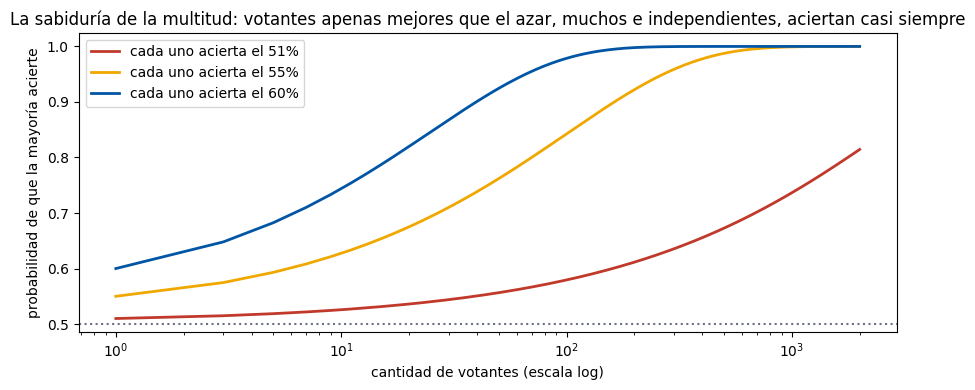

In [2]:
from scipy.stats import binom

ns = [1, 11, 101, 1001, 10001]
for p in [0.51, 0.55, 0.60]:
    print(f"acierto individual {p:.0%}: probabilidad de que la mayoría acierte con n = " + " · ".join(f"{n}: {1 - binom.cdf(n // 2, n, p):.3f}" for n in ns))
fig, ax = plt.subplots(figsize=(9, 4))
nn = np.arange(1, 2001, 2)
for p, color in [(0.51, ROJO), (0.55, AMBAR), (0.60, AZUL)]:
    ax.plot(nn, 1 - binom.cdf(nn // 2, nn, p), color=color, lw=2, label=f"cada uno acierta el {p:.0%}")
ax.axhline(0.5, color=GRIS, ls=":"); ax.set_xscale("log"); ax.set_xlabel("cantidad de votantes (escala log)"); ax.set_ylabel("probabilidad de que la mayoría acierte"); ax.legend()
ax.set_title("La sabiduría de la multitud: votantes apenas mejores que el azar, muchos e independientes, aciertan casi siempre")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.2 · Solo si son independientes: dónde se equivoca cada modelo</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La condición del argumento es que se equivoquen en lugares distintos. Con el umbral de 0,5 eso no se puede ni mirar (los tres dicen siempre «no cae»), así que se usa el de 0,15: cuántos errores tiene cada uno, en cuántas filas se equivocan los tres a la vez y en cuántas la mayoría.</p></div>

Con umbral 0,5, filas marcadas como caída: logística 18 · vecinos 25 · árbol 7  (caídas reales: 759)
Con umbral 0.15 · errores sobre 5982: logística 1795 · vecinos 1677 · árbol 1767
Filas donde se equivoca al menos uno: 2904 · los tres a la vez: 781 · la mayoría (dos o tres): 1554 → errores de la votación rígida


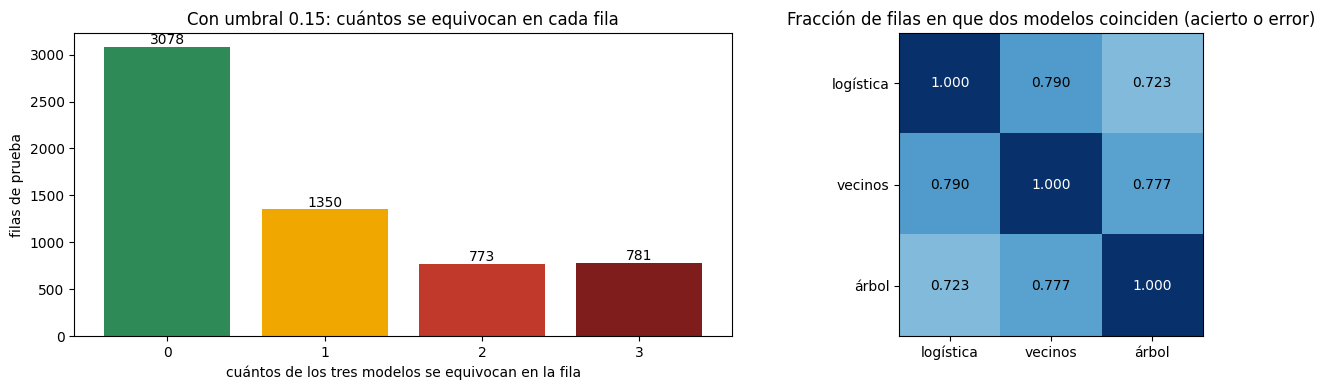

In [3]:
probs_ref = {"logística": logistica.predict_proba(X_pru)[:, 1], "vecinos": vecinos.predict_proba(X_pru)[:, 1], "árbol": arbol.predict_proba(X_pru)[:, 1]}
print("Con umbral 0,5, filas marcadas como caída: " + " · ".join(f"{k} {int((p >= 0.5).sum())}" for k, p in probs_ref.items()) + f"  (caídas reales: {y_pru.sum()})")
errores = pd.DataFrame({k: (p >= UMBRAL_ALT).astype(int) != y_pru.to_numpy() for k, p in probs_ref.items()}, index=X_pru.index)
cuantos = errores.sum(axis=1)
print(f"Con umbral {UMBRAL_ALT} · errores sobre {len(X_pru)}: " + " · ".join(f"{k} {errores[k].sum()}" for k in errores))
print(f"Filas donde se equivoca al menos uno: {(cuantos >= 1).sum()} · los tres a la vez: {(cuantos == 3).sum()} · la mayoría (dos o tres): {(cuantos >= 2).sum()} → errores de la votación rígida")
acuerdo = pd.DataFrame({a: {b: np.mean(errores[a] == errores[b]) for b in errores} for a in errores})
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4))
conteo = cuantos.value_counts().sort_index()
a.bar(conteo.index, conteo.values, color=[VERDE, AMBAR, ROJO, "#7f1d1d"][:len(conteo)]); a.set_xticks([0, 1, 2, 3]); a.set_xlabel("cuántos de los tres modelos se equivocan en la fila"); a.set_ylabel("filas de prueba")
for k, v in zip(conteo.index, conteo.values): a.text(k, v + 30, str(v), ha="center")
a.set_title(f"Con umbral {UMBRAL_ALT}: cuántos se equivocan en cada fila")
im = b.imshow(acuerdo, cmap="Blues", vmin=0.5, vmax=1); b.set_xticks(range(3)); b.set_xticklabels(acuerdo.columns); b.set_yticks(range(3)); b.set_yticklabels(acuerdo.index)
for i in range(3):
    for j in range(3): b.text(j, i, f"{acuerdo.iloc[i, j]:.3f}", ha="center", va="center", color="white" if acuerdo.iloc[i, j] > 0.85 else "black")
b.set_title("Fracción de filas en que dos modelos coinciden (acierto o error)")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con el umbral bajo hay muchos más errores que en la cátedra (es un problema difícil y el umbral prioriza no perderse caídas), y los tres modelos coinciden bastante menos entre sí que allá: hay filas donde se equivoca uno solo, que es donde votar puede corregir. Esa diversidad es la materia prima del ensamble.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">B · Votar: rígida y blanda</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.1 · La sentencia: VotingClassifier, rígida y blanda</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">VotingClassifier(integrantes, voting="hard")</code> vota con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">predict</code>, es decir con 0,5: acá eso es la línea de base con otro nombre. Por eso se agrega la votación rígida <b>a mano</b> con el umbral de 0,15 (cada modelo vota con su decisión, gana la mayoría). La blanda (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">voting="soft"</code>) promedia probabilidades. Y la contraprueba: tres árboles iguales con distinta semilla.</p></div>

In [4]:
from sklearn.ensemble import VotingClassifier

integrantes = [("logística", preparado(LogisticRegression())), ("vecinos", preparado(KNeighborsClassifier(n_neighbors=101))), ("árbol", DecisionTreeClassifier(max_depth=10, min_samples_leaf=200, random_state=2026))]
def guardar_decision(nombre, pred, modelo):
    resultados[nombre] = {"exactitud": accuracy_score(y_pru, pred), "precisión": precision_score(y_pru, pred, zero_division=0), "exhaustividad": recall_score(y_pru, pred),
                          "F1": f1_score(y_pru, pred), "AUC": np.nan, "log-loss": np.nan, "ajuste (ms)": np.nan, "predicción (ms)": np.nan, "modelo": modelo}
rigida = VotingClassifier(integrantes, voting="hard").fit(X_ent, y_ent)
guardar_decision("votación rígida con 0,5 (VotingClassifier)", rigida.predict(X_pru), rigida)
pred_rigida15 = (cuantos.index.map(lambda i: 0) + sum((p >= UMBRAL_ALT).astype(int) for p in probs_ref.values()) >= 2).astype(int)
guardar_decision(f"votación rígida a mano, umbral {UMBRAL_ALT}", np.asarray(pred_rigida15), None)
blanda = registrar("votación blanda (logística + vecinos + árbol)", VotingClassifier(integrantes, voting="soft"))
parecidos = registrar("votación blanda (tres árboles iguales)", VotingClassifier([(f"árbol {s}", DecisionTreeClassifier(max_depth=10, min_samples_leaf=200, random_state=s)) for s in range(3)], voting="soft"))
print(f"VotingClassifier rígida: filas marcadas como caída {int(rigida.predict(X_pru).sum())} de {len(X_pru)} → igual a la línea de base")
for k in ["regresión logística (clase 32)", "k vecinos, k=101 (clase 34)", "árbol, profundidad 10, mínimo 200 (clase 35)", "votación blanda (logística + vecinos + árbol)", "votación blanda (tres árboles iguales)"]:
    r = resultados[k]; print(f"{k:48s} AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f}")
for k in ["logística", "vecinos", "árbol"]:
    print(f"   con umbral {UMBRAL_ALT}, {k:9s}: F1 {f1_score(y_pru, probs_ref[k] >= UMBRAL_ALT):.3f}")
r = resultados[f"votación rígida a mano, umbral {UMBRAL_ALT}"]; print(f"   votación rígida a mano, umbral {UMBRAL_ALT}: F1 {r['F1']:.3f} · se equivoca en {int((np.asarray(pred_rigida15) != y_pru.to_numpy()).sum())} filas = las {int((cuantos >= 2).sum())} de A.2")
fila_ej = X_pru.iloc[[4]]
print(f"Probabilidad blanda de una fila: {blanda.predict_proba(fila_ej)[0, 1]:.3f} = promedio de " + ", ".join(f"{m.predict_proba(fila_ej)[0, 1]:.3f}" for m in blanda.named_estimators_.values()))

VotingClassifier rígida: filas marcadas como caída 4 de 5982 → igual a la línea de base
regresión logística (clase 32)                   AUC 0.663 · log-loss 0.365
k vecinos, k=101 (clase 34)                      AUC 0.741 · log-loss 0.343
árbol, profundidad 10, mínimo 200 (clase 35)     AUC 0.724 · log-loss 0.343
votación blanda (logística + vecinos + árbol)    AUC 0.744 · log-loss 0.338
votación blanda (tres árboles iguales)           AUC 0.724 · log-loss 0.343
   con umbral 0.15, logística: F1 0.306
   con umbral 0.15, vecinos  : F1 0.370
   con umbral 0.15, árbol    : F1 0.343
   votación rígida a mano, umbral 0.15: F1 0.372 · se equivoca en 1554 filas = las 1554 de A.2
Probabilidad blanda de una fila: 0.059 = promedio de 0.094, 0.069, 0.013


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La blanda queda <b>por encima de la logística y del árbol, y apenas por encima de los vecinos</b>: promediar tres modelos que se equivocan en lugares distintos ordena mejor que dos de ellos solos, sin superar claramente al mejor. Tres árboles iguales no suman nada: con los frenos, la semilla no cambia el árbol, y promediar tres copias da la misma copia. Diversos, no parecidos.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Tres fronteras, una mayoría</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Dos columnas (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">volatilidad</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">log_tamano</code>), los tres modelos y su promedio. El color es la probabilidad de caída, porque con este desbalance la frontera de 0,5 no aparece.</p></div>

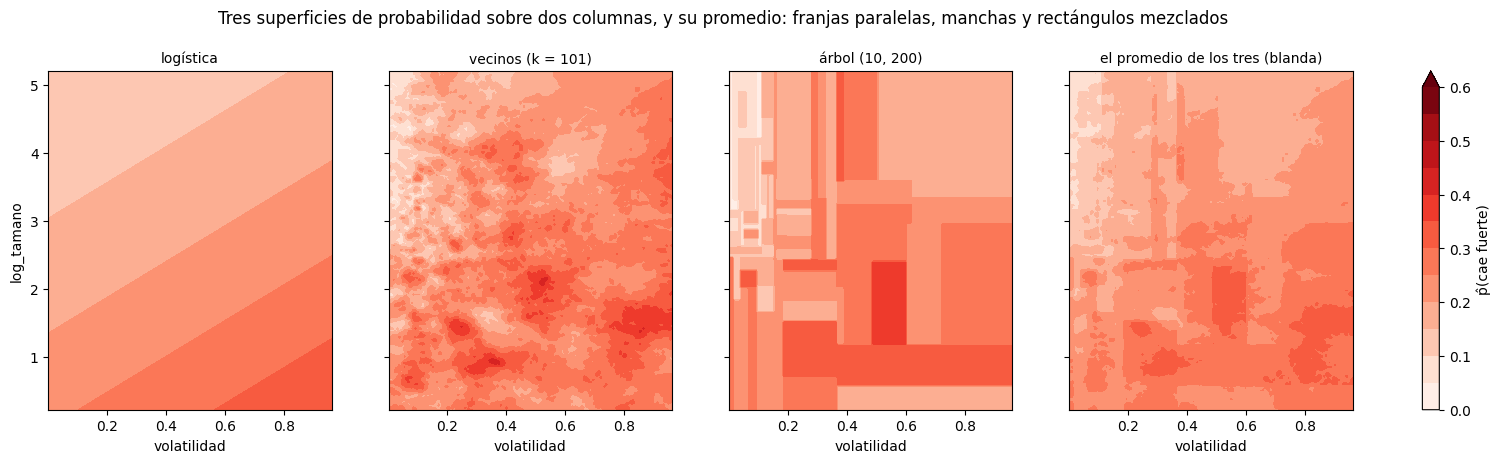

In [5]:
DOS = ["volatilidad", "log_tamano"]
lim1, lim2 = np.nanpercentile(X_ent[DOS[0]], [1, 97]), np.nanpercentile(X_ent[DOS[1]], [2, 99])
g1, g2 = np.meshgrid(np.linspace(*lim1, 160), np.linspace(*lim2, 160))
grilla = pd.DataFrame(np.c_[g1.ravel(), g2.ravel()], columns=DOS)
modelos2 = [("logística", preparado(LogisticRegression())), ("vecinos (k = 101)", preparado(KNeighborsClassifier(101))), ("árbol (10, 200)", DecisionTreeClassifier(max_depth=10, min_samples_leaf=200, random_state=2026))]
superficies = [m.fit(X_ent[DOS], y_ent).predict_proba(grilla)[:, 1].reshape(g1.shape) for _, m in modelos2]
superficies.append(np.mean(superficies, axis=0))
fig, ejes = plt.subplots(1, 4, figsize=(18, 4.4), sharey=True)
for ax, sup, nombre in zip(ejes, superficies, [n for n, _ in modelos2] + ["el promedio de los tres (blanda)"]):
    im = ax.contourf(g1, g2, sup, levels=np.linspace(0, 0.6, 13), cmap="Reds", extend="max")
    ax.set_title(nombre, fontsize=10); ax.set_xlabel("volatilidad")
ejes[0].set_ylabel("log_tamano")
fig.colorbar(im, ax=ejes, label="p̂(cae fuerte)", fraction=0.015)
fig.suptitle("Tres superficies de probabilidad sobre dos columnas, y su promedio: franjas paralelas, manchas y rectángulos mezclados", y=1.02)
plt.show()

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">C · Remuestrear: bagging, pasting, fuera de la bolsa</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.1 · Con y sin reposición</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Las bolsas de la diapositiva, en números, igual que en la cátedra. La cuenta del 63 % se verifica con las 31 000 filas.</p></div>

In [6]:
rng = np.random.default_rng(2026)
filas = np.arange(1, 11)
print("Diez filas, tres bolsas con reposición (bagging):")
for k in range(3):
    bolsa = np.sort(rng.choice(filas, size=10, replace=True)); afuera = sorted(int(v) for v in set(filas) - set(bolsa))
    print(f"  bolsa {k + 1}: {bolsa.tolist()} · repetidas: {10 - len(set(bolsa))} · fuera de la bolsa: {afuera}")
print("Tres muestras sin reposición (pasting), de 7 filas:")
for k in range(3):
    print(f"  muestra {k + 1}: {np.sort(rng.choice(filas, size=7, replace=False)).tolist()}")
m = len(X_ent)
vistas = [len(np.unique(rng.choice(m, size=m, replace=True))) / m for _ in range(200)]
print(f"Con {m} filas, 200 bolsas de {m} con reposición: cada una ve el {np.mean(vistas) * 100:.1f} % de las filas distintas (teoría: 1 − e⁻¹ = {(1 - np.exp(-1)) * 100:.1f} %)")

Diez filas, tres bolsas con reposición (bagging):
  bolsa 1: [1, 1, 2, 4, 4, 4, 5, 7, 7, 9] · repetidas: 4 · fuera de la bolsa: [3, 6, 8, 10]
  bolsa 2: [1, 2, 3, 7, 8, 8, 8, 9, 9, 10] · repetidas: 3 · fuera de la bolsa: [4, 5, 6]
  bolsa 3: [2, 2, 3, 6, 7, 7, 8, 8, 10, 10] · repetidas: 4 · fuera de la bolsa: [1, 4, 5, 9]
Tres muestras sin reposición (pasting), de 7 filas:
  muestra 1: [2, 3, 4, 5, 7, 8, 9]
  muestra 2: [1, 2, 4, 5, 6, 9, 10]
  muestra 3: [2, 3, 4, 7, 8, 9, 10]
Con 31415 filas, 200 bolsas de 31415 con reposición: cada una ve el 63.2 % de las filas distintas (teoría: 1 − e⁻¹ = 63.2 %)


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.2 · La sentencia: BaggingClassifier, bagging y pasting</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">BaggingClassifier(DecisionTreeClassifier(), n_estimators=500, max_samples=100, bootstrap=True, oob_score=True)</code>: quinientos árboles sin freno de cien filas cada uno. <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">bootstrap=False</code> es pasting. Y una bolsa con todas las filas (200 árboles, para no tardar demasiado). Los árboles aceptan faltantes, así que la bolsa también.</p></div>

In [7]:
from sklearn.ensemble import BaggingClassifier

bolsa100 = registrar("bagging: 500 árboles de 100 filas", BaggingClassifier(DecisionTreeClassifier(), n_estimators=500, max_samples=100, bootstrap=True, oob_score=True, random_state=2026, n_jobs=-1))
pasting100 = registrar("pasting: 500 árboles de 100 filas", BaggingClassifier(DecisionTreeClassifier(), n_estimators=500, max_samples=100, bootstrap=False, random_state=2026, n_jobs=-1))
bolsa = registrar("bagging: 200 árboles de 31 415 filas", BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, bootstrap=True, oob_score=True, random_state=2026, n_jobs=-1))
for k in ["árbol, profundidad 10, mínimo 200 (clase 35)", "bagging: 500 árboles de 100 filas", "pasting: 500 árboles de 100 filas", "bagging: 200 árboles de 31 415 filas"]:
    r = resultados[k]; print(f"{k:44s} AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f} · ajuste {r['ajuste (ms)']:,.0f} ms")
print(f"Un árbol de 100 filas, solo: AUC {roc_auc_score(y_pru, bolsa100.estimators_[0].predict_proba(X_pru.to_numpy())[:, 1]):.3f} · profundidad {bolsa100.estimators_[0].get_depth()} · los 500 agregados: {resultados['bagging: 500 árboles de 100 filas']['AUC']:.3f}")
un_sf = DecisionTreeClassifier(random_state=2026).fit(X_ent, y_ent)
print(f"Un árbol sin freno con todas las filas: AUC {roc_auc_score(y_pru, un_sf.predict_proba(X_pru)[:, 1]):.3f} · 200 agregados: {resultados['bagging: 200 árboles de 31 415 filas']['AUC']:.3f}")

árbol, profundidad 10, mínimo 200 (clase 35) AUC 0.724 · log-loss 0.343 · ajuste 150 ms
bagging: 500 árboles de 100 filas            AUC 0.741 · log-loss 0.345 · ajuste 13,765 ms
pasting: 500 árboles de 100 filas            AUC 0.741 · log-loss 0.345 · ajuste 1,016 ms
bagging: 200 árboles de 31 415 filas         AUC 0.722 · log-loss 0.367 · ajuste 9,633 ms
Un árbol de 100 filas, solo: AUC 0.602 · profundidad 9 · los 500 agregados: 0.741
Un árbol sin freno con todas las filas: AUC 0.577 · 200 agregados: 0.722


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Acá está la fuerza del promediado. Un árbol de cien filas solo es casi inútil (AUC ~0,60), y un árbol sin freno con todas las filas daba ~0,58 en la clase 35. Quinientos árboles de cien filas, promediados, <b>igualan a los vecinos</b>, lo mejor de la unidad 6. Y un detalle que en la cátedra no aparecía: doscientos árboles sin freno con <b>todas</b> las filas quedan por debajo de los de cien. Cada uno memoriza miles de hojas de ruido y, como ven casi los mismos datos, se equivocan parecido: menos diversidad. Con bolsas chicas, cada árbol es peor pero se equivocan en lugares más distintos.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Un árbol contra muchos</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Las dos columnas de antes: un árbol sin freno contra 300 árboles de mil filas agregados.</p></div>

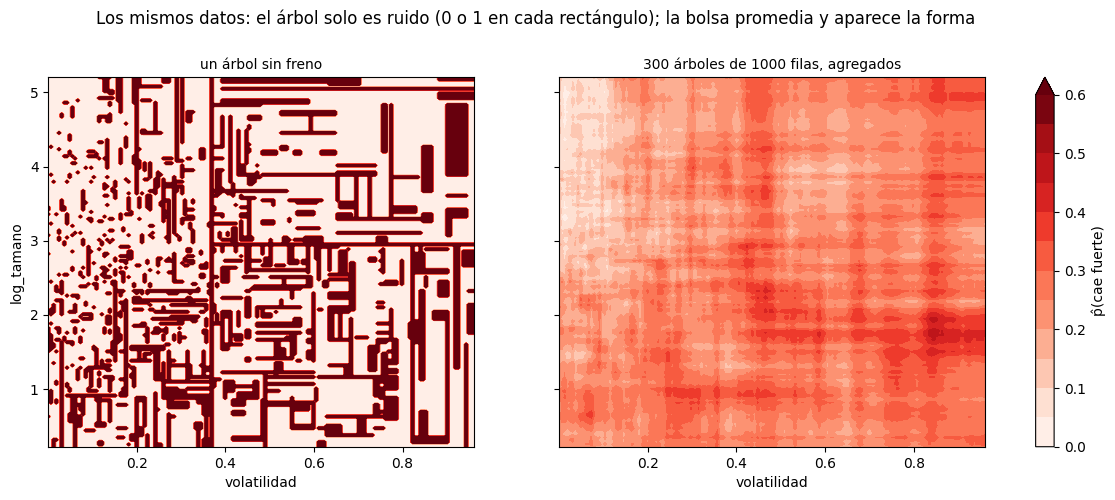

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, modelo_f, nombre in [(ejes[0], DecisionTreeClassifier(random_state=2026), "un árbol sin freno"), (ejes[1], BaggingClassifier(DecisionTreeClassifier(), n_estimators=300, max_samples=1000, random_state=2026, n_jobs=-1), "300 árboles de 1000 filas, agregados")]:
    modelo_f.fit(X_ent[DOS], y_ent)
    im = ax.contourf(g1, g2, modelo_f.predict_proba(grilla)[:, 1].reshape(g1.shape), levels=np.linspace(0, 0.6, 13), cmap="Reds", extend="max")
    ax.set_title(nombre, fontsize=10); ax.set_xlabel("volatilidad")
ejes[0].set_ylabel("log_tamano")
fig.colorbar(im, ax=ejes, label="p̂(cae fuerte)", fraction=0.02)
fig.suptitle("Los mismos datos: el árbol solo es ruido (0 o 1 en cada rectángulo); la bolsa promedia y aparece la forma", y=1.02)
plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.3 · Fuera de la bolsa, y por qué acá no alcanza</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Cada fila queda afuera de ~37 % de los árboles. <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">oob_score_</code> evalúa cada fila con los árboles que no la vieron: una estimación gratis, sin apartar datos. Pero con datos ordenados en el tiempo no mide lo mismo que la prueba: las filas que quedan afuera son de todos los meses del entrenamiento (y sus vecinas en el tiempo, el mismo agente el mes anterior, sí entraron), mientras que la prueba es el futuro. Se compara el AUC fuera de la bolsa con el de prueba.</p></div>

Cada fila quedó afuera de 74 árboles en promedio (de 200; teoría: 74), entre 46 y 104
AUC fuera de la bolsa: 0.692 · AUC sobre prueba: 0.722 · exactitud oob_score_: 0.815


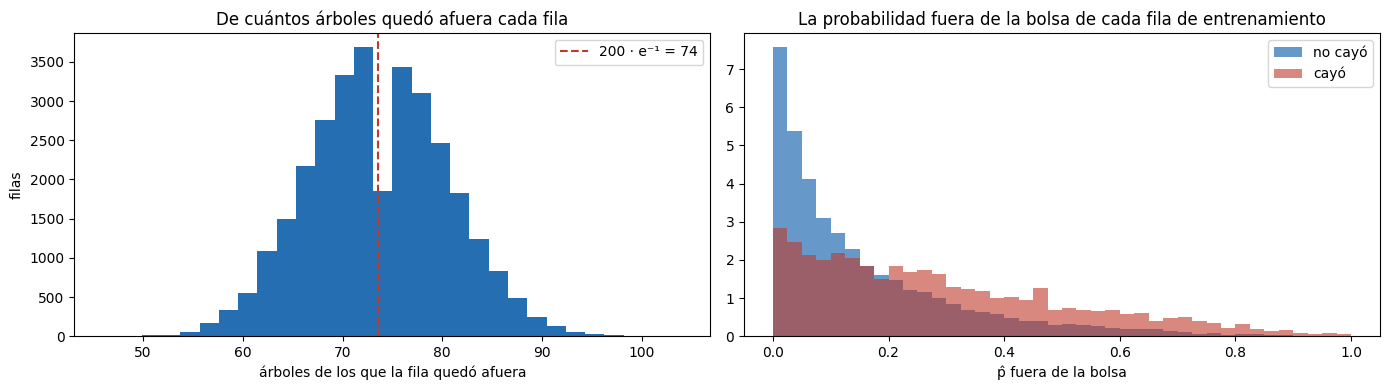

In [9]:
afuera = np.full(len(X_ent), bolsa.n_estimators)
for indices in bolsa.estimators_samples_:
    afuera[np.unique(indices)] -= 1
print(f"Cada fila quedó afuera de {afuera.mean():.0f} árboles en promedio (de {bolsa.n_estimators}; teoría: {bolsa.n_estimators * np.exp(-1):.0f}), entre {afuera.min()} y {afuera.max()}")
prob_oob = bolsa.oob_decision_function_[:, 1]
auc_oob = roc_auc_score(y_ent, prob_oob)
print(f"AUC fuera de la bolsa: {auc_oob:.3f} · AUC sobre prueba: {resultados['bagging: 200 árboles de 31 415 filas']['AUC']:.3f} · exactitud oob_score_: {bolsa.oob_score_:.3f}")
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4))
a.hist(afuera, bins=30, color=AZUL, alpha=0.85); a.axvline(bolsa.n_estimators * np.exp(-1), color=ROJO, ls="--", label=f"{bolsa.n_estimators} · e⁻¹ = {bolsa.n_estimators * np.exp(-1):.0f}"); a.set_xlabel("árboles de los que la fila quedó afuera"); a.set_ylabel("filas"); a.legend(); a.set_title("De cuántos árboles quedó afuera cada fila")
b.hist(prob_oob[y_ent == 0], bins=40, color=AZUL, alpha=0.6, label="no cayó", density=True); b.hist(prob_oob[y_ent == 1], bins=40, color=ROJO, alpha=0.6, label="cayó", density=True); b.set_xlabel("p̂ fuera de la bolsa"); b.legend()
b.set_title("La probabilidad fuera de la bolsa de cada fila de entrenamiento")
plt.tight_layout(); plt.show()

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La cuenta del 37 % se cumple. Pero el AUC fuera de la bolsa no coincide con el de prueba (acá sale más bajo): una mide sobre meses mezclados del pasado, la otra sobre un período posterior con otra proporción de caídas. En la cátedra los clientes eran intercambiables y las dos estimaciones casi coincidían; acá no hay garantía de que coincidan, ni en qué dirección se van a separar. Para elegir algo se usa la validación cruzada temporal, que al menos imita la situación real: entrenar con el pasado y evaluar con lo que viene después.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.4 · Parches y subespacios</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Muestrear también los atributos: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">max_features</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">bootstrap_features</code>. Se usan árboles de mil filas para que la comparación sea rápida.</p></div>

In [10]:
registrar("bagging: 300 árboles de 1000 filas", BaggingClassifier(DecisionTreeClassifier(), n_estimators=300, max_samples=1000, random_state=2026, n_jobs=-1))
parches = registrar("parches: 300 árboles, 1000 filas y 50 % de columnas", BaggingClassifier(DecisionTreeClassifier(), n_estimators=300, max_samples=1000, max_features=0.5, bootstrap=True, random_state=2026, n_jobs=-1))
subespacios = registrar("subespacios: 100 árboles, todas las filas, 50 % de columnas", BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, max_samples=1.0, max_features=0.5, bootstrap=False, random_state=2026, n_jobs=-1))
for k in ["bagging: 300 árboles de 1000 filas", "parches: 300 árboles, 1000 filas y 50 % de columnas", "subespacios: 100 árboles, todas las filas, 50 % de columnas"]:
    r = resultados[k]; print(f"{k:58s} AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f}")
print(f"Columnas que vio el primer árbol de los parches: {[PREDICTORAS[j] for j in parches.estimators_features_[0]]}")

bagging: 300 árboles de 1000 filas                         AUC 0.746 · log-loss 0.339
parches: 300 árboles, 1000 filas y 50 % de columnas        AUC 0.744 · log-loss 0.343
subespacios: 100 árboles, todas las filas, 50 % de columnas AUC 0.693 · log-loss 0.367
Columnas que vio el primer árbol de los parches: ['es_residencial', 'ratio_dias', 'var_mes_ant', 'es_gran_usuario']


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.5 · Sesgo parecido, menos varianza</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La clase 35 midió la varianza de un árbol. Se repite: diez modelos sobre diez submuestras del 95 %, y cuántas decisiones (con umbral 0,15) cambian respecto del primero. La bolsa, con 100 árboles de mil filas para que el experimento no tarde.</p></div>

In [11]:
rng = np.random.default_rng(2026)
cambios = {"un árbol sin freno": [], "un árbol (10, 200)": [], "bagging, 100 árboles de 1000 filas": []}
base_pred = {}
for s in range(10):
    idx = np.sort(rng.choice(len(X_ent), int(0.95 * len(X_ent)), replace=False))
    for nombre, m in [("un árbol sin freno", DecisionTreeClassifier(random_state=2026)), ("un árbol (10, 200)", DecisionTreeClassifier(max_depth=10, min_samples_leaf=200, random_state=2026)),
                      ("bagging, 100 árboles de 1000 filas", BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, max_samples=1000, random_state=2026, n_jobs=-1))]:
        pred = (m.fit(X_ent.iloc[idx], y_ent.iloc[idx]).predict_proba(X_pru)[:, 1] >= UMBRAL_ALT).astype(int)
        if s == 0: base_pred[nombre] = pred
        else: cambios[nombre].append(int((pred != base_pred[nombre]).sum()))
for nombre, v in cambios.items(): print(f"{nombre:36s} decisiones distintas del primero, en nueve submuestras del 95 %: {v} · promedio {np.mean(v):.0f} de {len(X_pru)}")

un árbol sin freno                   decisiones distintas del primero, en nueve submuestras del 95 %: [1210, 1265, 1179, 1295, 1193, 1202, 1013, 1221, 1152] · promedio 1192 de 5982
un árbol (10, 200)                   decisiones distintas del primero, en nueve submuestras del 95 %: [807, 885, 925, 856, 780, 920, 532, 844, 647] · promedio 800 de 5982
bagging, 100 árboles de 1000 filas   decisiones distintas del primero, en nueve submuestras del 95 %: [680, 704, 666, 723, 700, 642, 758, 777, 758] · promedio 712 de 5982


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Un árbol sin freno cambia más de mil decisiones con un 5 % menos de filas: es casi ruido. El árbol con frenos cambia unos cientos. La bolsa, aun con árboles sin freno adentro, cambia menos que el árbol frenado: la agregación compra estabilidad sin pedirle a cada árbol que se frene.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">D · Bosques: árboles con filas y atributos al azar</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.1 · La sentencia: RandomForestClassifier</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">RandomForestClassifier(n_estimators=500)</code>: una bolsa de árboles con una aleatoriedad más, √n columnas al azar en cada nodo (acá √8 → 2). Se registra el de la sentencia (árboles sin freno) y se verifica la equivalencia con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">BaggingClassifier</code> de árboles con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">max_features="sqrt"</code> (con 200 árboles cada uno, para que la comparación no tarde).</p></div>

In [12]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

bosque_sf = registrar("bosque aleatorio: 500 árboles sin freno", RandomForestClassifier(n_estimators=500, oob_score=True, random_state=2026, n_jobs=-1))
bosque200 = registrar("bosque aleatorio: 200 árboles sin freno", RandomForestClassifier(n_estimators=200, random_state=2026, n_jobs=-1))
equivalente = registrar("bagging de 200 árboles con max_features=\"sqrt\" (equivale al bosque)", BaggingClassifier(DecisionTreeClassifier(max_features="sqrt"), n_estimators=200, bootstrap=True, random_state=2026, n_jobs=-1))
for k in ["bagging: 200 árboles de 31 415 filas", "bosque aleatorio: 200 árboles sin freno", "bagging de 200 árboles con max_features=\"sqrt\" (equivale al bosque)", "bosque aleatorio: 500 árboles sin freno"]:
    r = resultados[k]; print(f"{k:66s} AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f} · ajuste {r['ajuste (ms)']:,.0f} ms")
print(f"Columnas por nodo: {bosque_sf.max_features} = √8 → {max(1, int(np.sqrt(8)))} · profundidad media de los árboles: {np.mean([a.get_depth() for a in bosque_sf.estimators_]):.0f} · hojas por árbol: {np.mean([a.get_n_leaves() for a in bosque_sf.estimators_]):,.0f}")

bagging: 200 árboles de 31 415 filas                               AUC 0.722 · log-loss 0.367 · ajuste 9,633 ms
bosque aleatorio: 200 árboles sin freno                            AUC 0.741 · log-loss 0.350 · ajuste 2,121 ms
bagging de 200 árboles con max_features="sqrt" (equivale al bosque) AUC 0.739 · log-loss 0.356 · ajuste 2,795 ms
bosque aleatorio: 500 árboles sin freno                            AUC 0.743 · log-loss 0.343 · ajuste 8,162 ms
Columnas por nodo: sqrt = √8 → 2 · profundidad media de los árboles: 41 · hojas por árbol: 4,984


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.2 · Un freno para el bosque, elegido con validación temporal</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">En la cátedra el bosque sin freno era lo mejor. Acá cada árbol sin freno memoriza miles de hojas de una fila, y el promedio arrastra parte de ese ruido. Se prueba <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">min_samples_leaf</code> con validación cruzada temporal (100 árboles por modelo, para que la búsqueda no tarde) y se registra el elegido con 500 árboles.</p></div>

In [13]:
filas_h = []
for h in [1, 10, 30, 100]:
    cv = cross_val_score(RandomForestClassifier(n_estimators=100, min_samples_leaf=h, random_state=2026, n_jobs=-1), X_ent, y_ent, cv=CV, scoring="roc_auc")
    filas_h.append({"min_samples_leaf": h, "AUC validación temporal": cv.mean(), "desvío": cv.std()})
tabla_h = pd.DataFrame(filas_h).set_index("min_samples_leaf")
HOJA = int(tabla_h["AUC validación temporal"].idxmax())
display(tabla_h.round(3))
NOMBRE_BOSQUE = f"bosque aleatorio: 500 árboles, mínimo {HOJA} por hoja (validación)"
bosque = registrar(NOMBRE_BOSQUE, RandomForestClassifier(n_estimators=500, min_samples_leaf=HOJA, oob_score=True, random_state=2026, n_jobs=-1))
for k in ["bosque aleatorio: 500 árboles sin freno", NOMBRE_BOSQUE, "k vecinos, k=101 (clase 34)"]:
    r = resultados[k]; print(f"{k:58s} AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f}")
print(f"Hojas por árbol: sin freno {np.mean([a.get_n_leaves() for a in bosque_sf.estimators_]):,.0f} · con mínimo {HOJA}: {np.mean([a.get_n_leaves() for a in bosque.estimators_]):,.0f}")

,AUC validación temporal,desvío
min_samples_leaf,,
1,0.657,0.040
10,0.688,0.036
30,0.691,0.035
100,0.690,0.035


bosque aleatorio: 500 árboles sin freno                    AUC 0.743 · log-loss 0.343
bosque aleatorio: 500 árboles, mínimo 30 por hoja (validación) AUC 0.761 · log-loss 0.330
k vecinos, k=101 (clase 34)                                AUC 0.741 · log-loss 0.343
Hojas por árbol: sin freno 4,984 · con mínimo 30: 413


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El freno moderado gana en validación y también en prueba: el bosque con mínimo por hoja <b>supera a los vecinos</b>, que eran lo mejor de la unidad 6, en AUC y en log-loss. Con árboles más chicos, además, el modelo pesa mucho menos. La lección se ajusta: «quinientos árboles sin freno, sin elegir nada» funciona cuando los datos no son tan ruidosos; con un objetivo como este, conviene un freno suave, y la validación lo encuentra.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Quince árboles, y el bosque</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Quince árboles del bosque sobre dos columnas, cada uno con su bolsa y sus columnas sorteadas, y la probabilidad del bosque entero.</p></div>

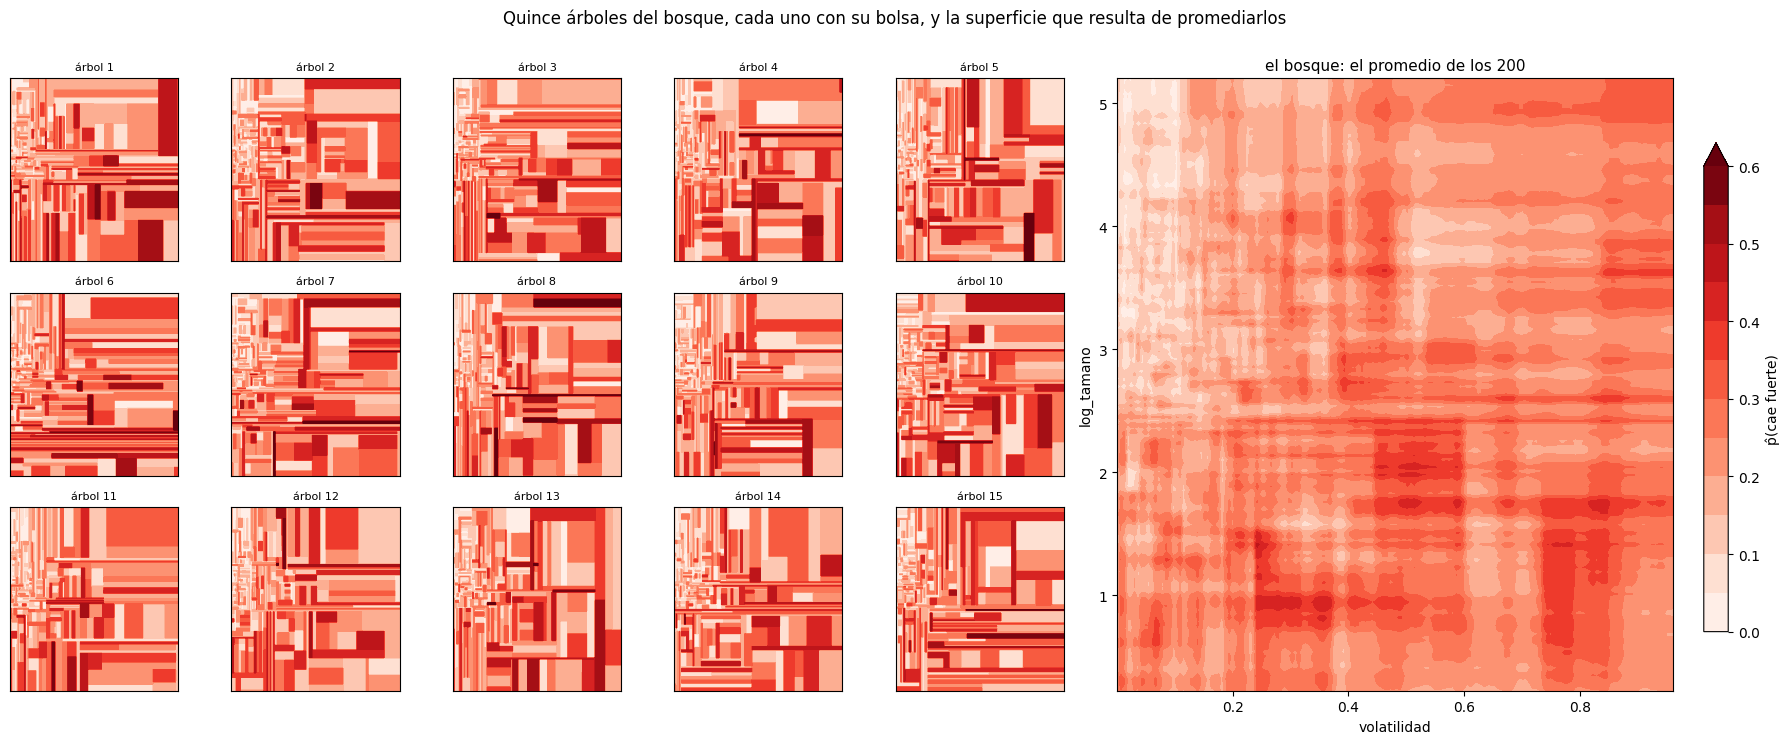

In [14]:
bosque2 = RandomForestClassifier(n_estimators=200, min_samples_leaf=HOJA, random_state=2026, n_jobs=-1).fit(X_ent[DOS], y_ent)
fig = plt.figure(figsize=(18, 7.4))
rejilla = fig.add_gridspec(3, 8)
for k in range(15):
    ax = fig.add_subplot(rejilla[k // 5, k % 5])
    ax.contourf(g1, g2, bosque2.estimators_[k].predict_proba(grilla.to_numpy())[:, 1].reshape(g1.shape), levels=np.linspace(0, 0.6, 13), cmap="Reds", extend="max")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"árbol {k + 1}", fontsize=8)
ax = fig.add_subplot(rejilla[:, 5:])
im = ax.contourf(g1, g2, bosque2.predict_proba(grilla)[:, 1].reshape(g1.shape), levels=np.linspace(0, 0.6, 13), cmap="Reds", extend="max")
ax.set_title("el bosque: el promedio de los 200", fontsize=11); ax.set_xlabel("volatilidad"); ax.set_ylabel("log_tamano")
fig.colorbar(im, ax=ax, label="p̂(cae fuerte)", fraction=0.04)
fig.suptitle("Quince árboles del bosque, cada uno con su bolsa, y la superficie que resulta de promediarlos", y=1.0)
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.3 · Umbrales al azar: extra-árboles</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ExtraTreesClassifier</code>: además de los atributos al azar, umbrales al azar. Más rápido. Con y sin el mismo mínimo por hoja, y la validación temporal de los dos (100 árboles).</p></div>

In [15]:
extra_sf = registrar("extra-árboles: 500 árboles sin freno", ExtraTreesClassifier(n_estimators=500, random_state=2026, n_jobs=-1))
NOMBRE_EXTRA = f"extra-árboles: 500 árboles, mínimo {HOJA} por hoja"
extra = registrar(NOMBRE_EXTRA, ExtraTreesClassifier(n_estimators=500, min_samples_leaf=HOJA, random_state=2026, n_jobs=-1))
for nombre, m, k in [("bosque aleatorio", RandomForestClassifier(n_estimators=100, min_samples_leaf=HOJA, random_state=2026, n_jobs=-1), NOMBRE_BOSQUE),
                     ("extra-árboles", ExtraTreesClassifier(n_estimators=100, min_samples_leaf=HOJA, random_state=2026, n_jobs=-1), NOMBRE_EXTRA)]:
    cv = cross_val_score(m, X_ent, y_ent, cv=CV, scoring="roc_auc"); r = resultados[k]
    print(f"{nombre:18s} (mínimo {HOJA}) AUC validación temporal {cv.mean():.3f} ± {cv.std():.3f} · AUC prueba {r['AUC']:.3f} · log-loss {r['log-loss']:.3f} · ajuste {r['ajuste (ms)']:,.0f} ms")
print(f"extra-árboles sin freno: AUC {resultados['extra-árboles: 500 árboles sin freno']['AUC']:.3f} · log-loss {resultados['extra-árboles: 500 árboles sin freno']['log-loss']:.3f}")

bosque aleatorio   (mínimo 30) AUC validación temporal 0.691 ± 0.035 · AUC prueba 0.761 · log-loss 0.330 · ajuste 6,612 ms
extra-árboles      (mínimo 30) AUC validación temporal 0.669 ± 0.038 · AUC prueba 0.751 · log-loss 0.348 · ajuste 2,000 ms
extra-árboles sin freno: AUC 0.738 · log-loss 0.351


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.4 · ¿Cuántos árboles?</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El AUC sobre prueba y el AUC fuera de la bolsa a medida que se agregan árboles, con el mínimo por hoja elegido.</p></div>

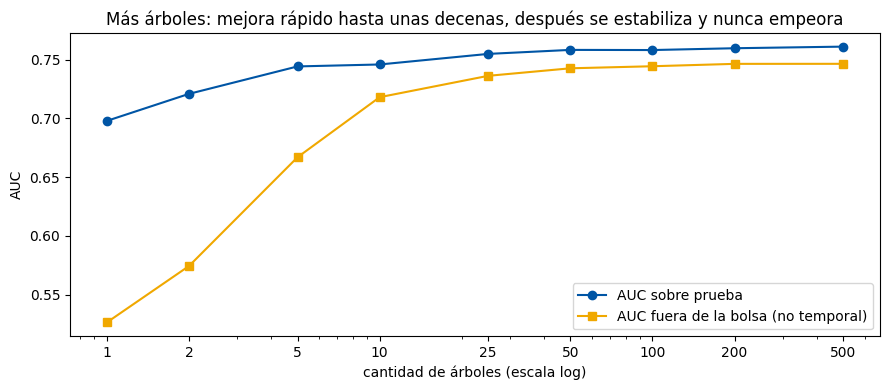

1: 0.698 · 2: 0.721 · 5: 0.744 · 10: 0.746 · 25: 0.755 · 50: 0.758 · 100: 0.758 · 200: 0.760 · 500: 0.761


In [16]:
cantidades = [1, 2, 5, 10, 25, 50, 100, 200, 500]; auc_n, oob_n = [], []
for n in cantidades:
    m = RandomForestClassifier(n_estimators=n, min_samples_leaf=HOJA, oob_score=True, random_state=2026, n_jobs=-1).fit(X_ent, y_ent)
    auc_n.append(roc_auc_score(y_pru, m.predict_proba(X_pru)[:, 1]))
    ok = ~np.isnan(m.oob_decision_function_[:, 1]); oob_n.append(roc_auc_score(y_ent[ok], m.oob_decision_function_[ok, 1]))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(cantidades, auc_n, marker="o", color=AZUL, label="AUC sobre prueba"); ax.plot(cantidades, oob_n, marker="s", color=AMBAR, label="AUC fuera de la bolsa (no temporal)")
ax.set_xscale("log"); ax.set_xticks(cantidades); ax.set_xticklabels(cantidades); ax.set_xlabel("cantidad de árboles (escala log)"); ax.set_ylabel("AUC"); ax.legend()
ax.set_title("Más árboles: mejora rápido hasta unas decenas, después se estabiliza y nunca empeora")
plt.tight_layout(); plt.show()
print(" · ".join(f"{n}: {a:.3f}" for n, a in zip(cantidades, auc_n)))

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.5 · Las dos importancias</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">feature_importances_</code> (impureza, al entrenar) y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">permutation_importance</code> (sobre prueba, barajando cada columna, cinco repeticiones), sobre el bosque elegido.</p></div>

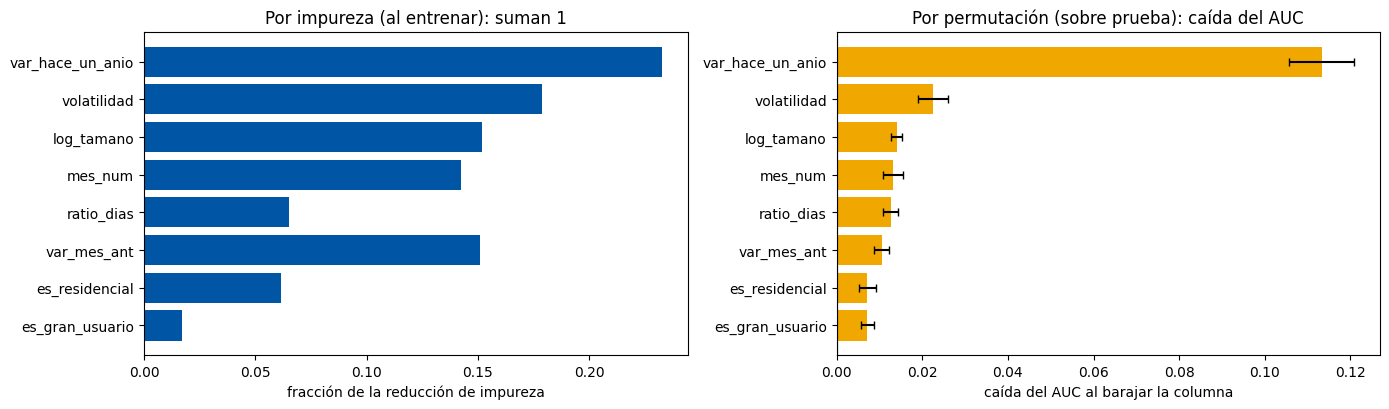

,por impureza,por permutación (caída de AUC),± desvío
var_hace_un_anio,0.2326,0.1132,0.0076
volatilidad,0.1790,0.0225,0.0035
log_tamano,0.1519,0.0140,0.0012
mes_num,0.1423,0.0132,0.0024
ratio_dias,0.0649,0.0127,0.0018
var_mes_ant,0.1508,0.0106,0.0017
es_residencial,0.0616,0.0072,0.0020
es_gran_usuario,0.0169,0.0071,0.0015


In [17]:
from sklearn.inspection import permutation_importance

imp_impureza = pd.Series(bosque.feature_importances_, index=PREDICTORAS)
permutacion = permutation_importance(bosque, X_pru, y_pru, scoring="roc_auc", n_repeats=5, random_state=2026, n_jobs=-1)
imp_perm = pd.Series(permutacion.importances_mean, index=PREDICTORAS); desvio_perm = pd.Series(permutacion.importances_std, index=PREDICTORAS)
orden = imp_perm.sort_values().index
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.2))
a.barh(orden, imp_impureza[orden], color=AZUL); a.set_title("Por impureza (al entrenar): suman 1"); a.set_xlabel("fracción de la reducción de impureza")
b.barh(orden, imp_perm[orden], xerr=desvio_perm[orden], color=AMBAR, capsize=3); b.axvline(0, color="black", lw=0.8); b.set_title("Por permutación (sobre prueba): caída del AUC"); b.set_xlabel("caída del AUC al barajar la columna")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"por impureza": imp_impureza, "por permutación (caída de AUC)": imp_perm, "± desvío": desvio_perm}).sort_values("por permutación (caída de AUC)", ascending=False).round(4))

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.6 · La impureza engaña</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Se agregan dos columnas que no dicen nada (un ruido continuo y un número de fila, todos distintos) y se vuelve a entrenar el bosque (200 árboles). Por impureza reciben importancia; por permutación sobre prueba, no.</p></div>

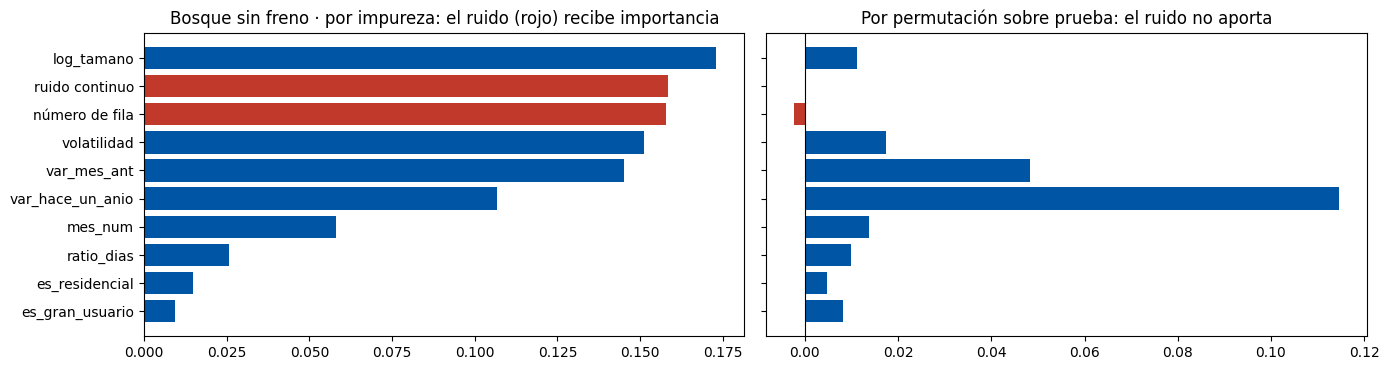

Bosque sin freno con ruido: AUC 0.741 · el ruido continuo queda 2.º de 10 por impureza


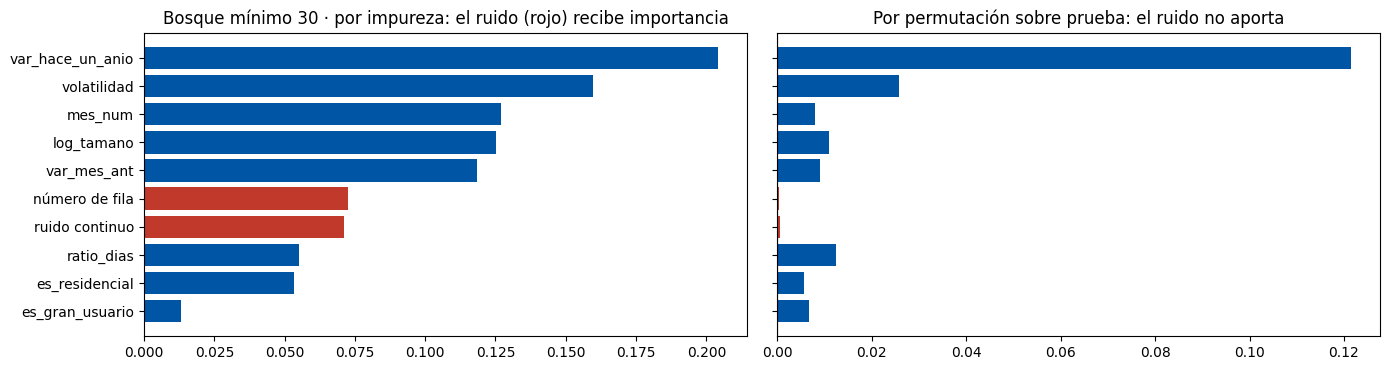

Bosque mínimo 30 con ruido: AUC 0.756 · el ruido continuo queda 7.º de 10 por impureza


In [18]:
rng = np.random.default_rng(2026)
X_ent_r, X_pru_r = X_ent.copy(), X_pru.copy()
X_ent_r["ruido continuo"] = rng.normal(size=len(X_ent)); X_pru_r["ruido continuo"] = rng.normal(size=len(X_pru))
X_ent_r["número de fila"] = rng.permutation(len(X_ent)).astype(float); X_pru_r["número de fila"] = rng.permutation(len(X_pru)).astype(float)
for nombre_b, hoja_b in [("sin freno", 1), (f"mínimo {HOJA}", HOJA)]:
    bosque_r = RandomForestClassifier(n_estimators=200, min_samples_leaf=hoja_b, random_state=2026, n_jobs=-1).fit(X_ent_r, y_ent)
    perm_r = permutation_importance(bosque_r, X_pru_r, y_pru, scoring="roc_auc", n_repeats=3, random_state=2026, n_jobs=-1)
    tabla_r = pd.DataFrame({"por impureza": bosque_r.feature_importances_, "por permutación": perm_r.importances_mean}, index=X_ent_r.columns).sort_values("por impureza", ascending=False)
    colores = [ROJO if ("ruido" in n or "número" in n) else AZUL for n in tabla_r.index]
    fig, (a, b) = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
    a.barh(tabla_r.index[::-1], tabla_r["por impureza"][::-1], color=colores[::-1]); a.set_title(f"Bosque {nombre_b} · por impureza: el ruido (rojo) recibe importancia")
    b.barh(tabla_r.index[::-1], tabla_r["por permutación"][::-1], color=colores[::-1]); b.axvline(0, color="black", lw=0.8); b.set_title("Por permutación sobre prueba: el ruido no aporta")
    plt.tight_layout(); plt.show()
    print(f"Bosque {nombre_b} con ruido: AUC {roc_auc_score(y_pru, bosque_r.predict_proba(X_pru_r)[:, 1]):.3f} · el ruido continuo queda {list(tabla_r.index).index('ruido continuo') + 1}.º de {len(tabla_r)} por impureza")

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con árboles sin freno, el ruido continuo y el número de fila quedan <b>entre las columnas más importantes por impureza</b>: con miles de hojas, cada árbol encuentra cortes en ellos que «purifican» nodos chicos. Por permutación no aportan nada. Con el mínimo por hoja el engaño se achica, porque los nodos chicos donde el ruido se aprovechaba ya no existen. La regla de la cátedra vale igual: qué columnas usa el bosque se lee con la permutación sobre datos no vistos.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">E · El comparativo: cuál resultó mejor, y cómo se elige</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La matriz, el AUC y la decisión</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Todo lo registrado. Las dos votaciones rígidas no tienen probabilidades: AUC y log-loss quedan vacíos.</p></div>

In [19]:
METRICAS = ["exactitud", "precisión", "exhaustividad", "F1", "AUC", "log-loss", "ajuste (ms)", "predicción (ms)"]
matriz = pd.DataFrame({k: {m: v[m] for m in METRICAS} for k, v in resultados.items()}).T.astype(float)
(matriz.style.format({m: "{:.3f}" for m in METRICAS[:6]}, na_rep="—").format({"ajuste (ms)": "{:,.0f}", "predicción (ms)": "{:,.0f}"}, na_rep="—")
       .background_gradient(subset=["exactitud", "precisión", "exhaustividad", "F1", "AUC"], cmap="RdYlGn")
       .background_gradient(subset=["log-loss", "ajuste (ms)", "predicción (ms)"], cmap="RdYlGn_r"))

,exactitud,precisión,exhaustividad,F1,AUC,log-loss,ajuste (ms),predicción (ms)
línea de base (mayoritaria),0.873119,0.000000,0.000000,0.000000,0.500000,4.573242,6,1
regresión logística (clase 32),0.873454,0.555556,0.013175,0.025740,0.662507,0.364760,73,4
"k vecinos, k=101 (clase 34)",0.873955,0.600000,0.019763,0.038265,0.741016,0.343047,100,"1,085"
"árbol, profundidad 10, mínimo 200 (clase 35)",0.873287,0.571429,0.005270,0.010444,0.724198,0.343223,150,2
"votación rígida con 0,5 (VotingClassifier)",0.873119,0.500000,0.002635,0.005242,—,—,—,—
"votación rígida a mano, umbral 0.15",0.740221,0.268222,0.606061,0.371867,—,—,—,—
votación blanda (logística + vecinos + árbol),0.873287,0.571429,0.005270,0.010444,0.743717,0.338413,298,"1,081"
votación blanda (tres árboles iguales),0.873287,0.571429,0.005270,0.010444,0.724198,0.343223,437,5
bagging: 500 árboles de 100 filas,0.873454,0.521739,0.031621,0.059627,0.740616,0.344806,"13,765",200
pasting: 500 árboles de 100 filas,0.873621,0.534884,0.030303,0.057357,0.740796,0.344563,"1,016",183


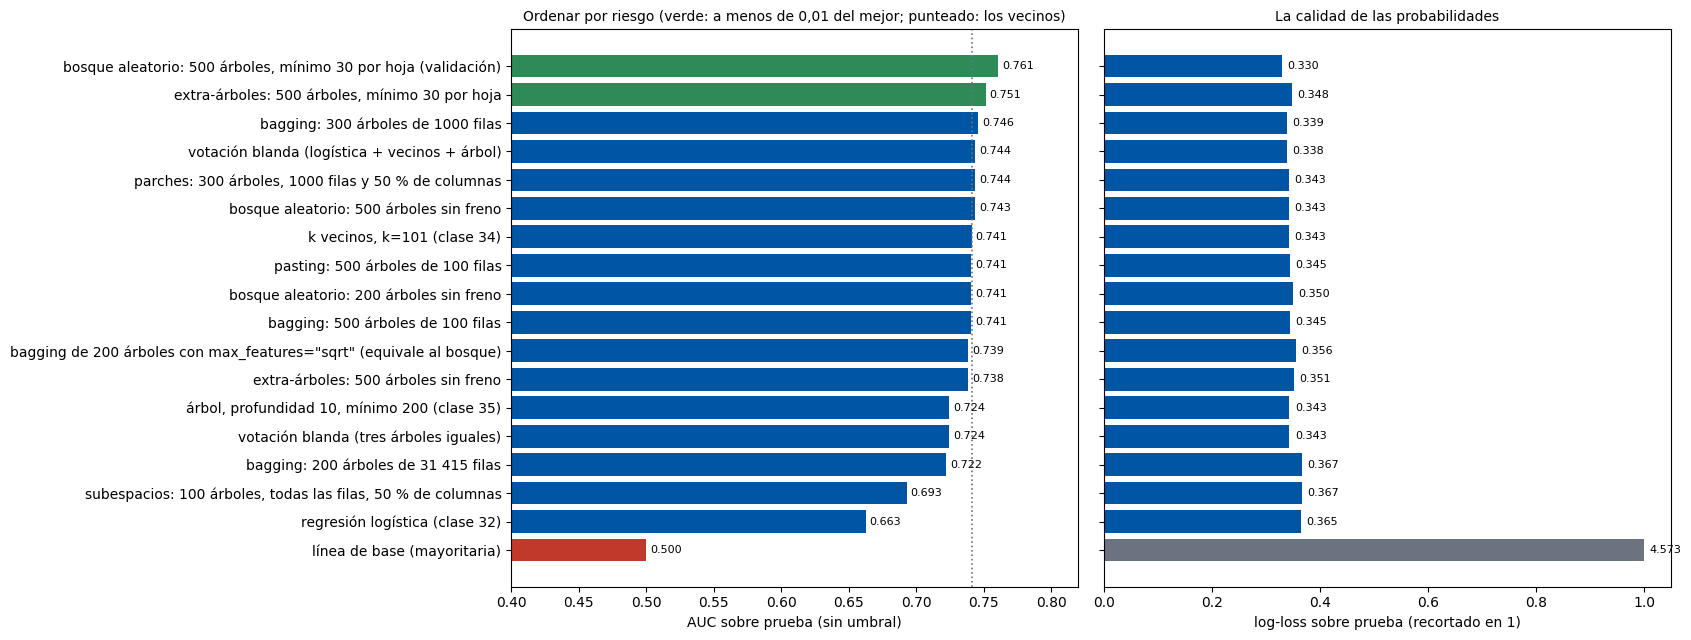

In [20]:
fig, (a, b) = plt.subplots(1, 2, figsize=(17, 6.5), sharey=True)
orden = matriz.dropna(subset=["AUC"]).sort_values("AUC", ascending=False)
mejor_auc = orden["AUC"].max()
a.barh(orden.index, orden["AUC"], color=[VERDE if v >= mejor_auc - 0.01 else (ROJO if v < 0.6 else AZUL) for v in orden["AUC"]]); a.invert_yaxis(); a.set_xlim(0.4, 0.82)
for k, v in enumerate(orden["AUC"]): a.text(v + 0.003, k, f"{v:.3f}", va="center", fontsize=8)
a.axvline(resultados["k vecinos, k=101 (clase 34)"]["AUC"], color=GRIS, ls=":", lw=1.2)
a.set_xlabel("AUC sobre prueba (sin umbral)"); a.set_title("Ordenar por riesgo (verde: a menos de 0,01 del mejor; punteado: los vecinos)", fontsize=10)
b.barh(orden.index, orden["log-loss"].clip(upper=1.0), color=[AZUL if v < 0.5 else GRIS for v in orden["log-loss"]])
for k, v in enumerate(orden["log-loss"]): b.text(min(v, 1.0) + 0.01, k, f"{v:.3f}", va="center", fontsize=8)
b.set_xlabel("log-loss sobre prueba (recortado en 1)"); b.set_title("La calidad de las probabilidades", fontsize=10)
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La elección</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">El bosque con freno suave</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">El bosque de 500 árboles con el mínimo por hoja elegido en validación temporal queda arriba de toda la unidad 6, incluidos los vecinos, en AUC y en log-loss. Los extra-árboles con el mismo freno quedan cerca. Es el elegido.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que cambió respecto de la cátedra</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Allá el bosque sin freno ganaba «sin elegir nada a mano». Acá, con un objetivo ruidoso y 31 000 filas, el sin freno apenas empata con los vecinos y pesa muchísimo; el freno moderado lo mejora y lo achica. Y lo que queda fuera de la bolsa no sirve para elegir: no imita la situación de predecir el futuro.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">La votación</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">La blanda de los tres modelos de la unidad 6 mejora a dos de ellos, sin pasar claramente al mejor. La rígida con 0,5 es la línea de base; con 0,15 es una decisión razonable, pero sin probabilidades.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se pierde</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">La lectura entera del árbol de la clase 35. Lo que queda: los votos de los árboles y la importancia por permutación.</td></tr></table></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">F · Usarlo: cada fila, con los votos de sus árboles</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Dos agentes nuevos, y cómo votaron los 500</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La probabilidad del bosque es el promedio de las de sus 500 árboles (cada uno da la fracción de caídas de su hoja). Con mínimo por hoja, cada árbol ya no vota 0 o 1: vota una proporción. Se muestra el reparto, y lo que dicen los modelos de la unidad 6.</p></div>

,ratio_dias,var_mes_ant,volatilidad,var_hace_un_anio,log_tamano,mes_num,es_gran_usuario,es_residencial,p̂ bosque,árboles con p̂ ≥ 0.15 (de 500),p̂ árbol solo,p̂ vecinos,p̂ logística
distribuidora grande · marzo,1.107143,0.02,0.02,0.08,4.903090,3,0,1,0.086,97,0.072,0.149,0.110
gran usuario chico · febrero,0.903226,0.60,0.60,NaN,2.176091,2,1,0,0.314,438,0.289,0.277,0.243


p̂ del bosque = promedio de los 500 árboles: [0.086 0.314] (coincide con predict_proba)


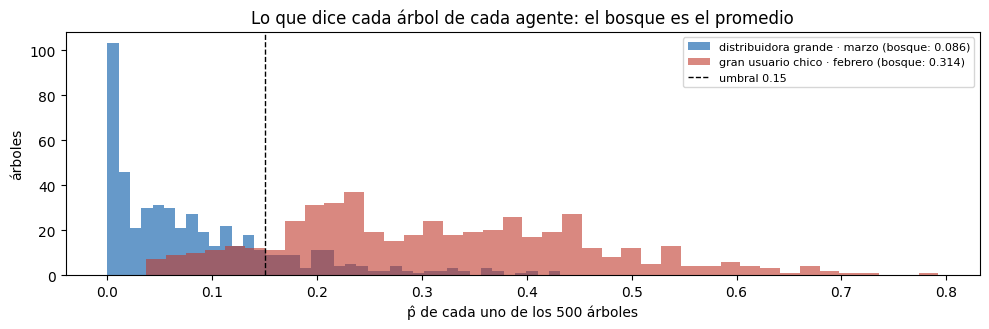

In [21]:
nuevo = pd.DataFrame([
    {"ratio_dias": 31 / 28, "var_mes_ant": 0.02, "volatilidad": 0.02, "var_hace_un_anio": 0.08, "log_tamano": np.log10(80000), "mes_num": 3, "es_gran_usuario": 0, "es_residencial": 1},
    {"ratio_dias": 28 / 31, "var_mes_ant": 0.60, "volatilidad": 0.60, "var_hace_un_anio": np.nan, "log_tamano": np.log10(150), "mes_num": 2, "es_gran_usuario": 1, "es_residencial": 0},
], index=["distribuidora grande · marzo", "gran usuario chico · febrero"])
votos = np.array([a.predict_proba(nuevo[PREDICTORAS].to_numpy())[:, 1] for a in bosque.estimators_])
nuevo["p̂ bosque"] = bosque.predict_proba(nuevo[PREDICTORAS])[:, 1].round(3)
nuevo[f"árboles con p̂ ≥ {UMBRAL_ALT} (de 500)"] = (votos >= UMBRAL_ALT).sum(axis=0)
nuevo["p̂ árbol solo"] = arbol.predict_proba(nuevo[PREDICTORAS])[:, 1].round(3)
nuevo["p̂ vecinos"] = vecinos.predict_proba(nuevo[PREDICTORAS])[:, 1].round(3)
nuevo["p̂ logística"] = logistica.predict_proba(nuevo[PREDICTORAS])[:, 1].round(3)
display(nuevo)
print(f"p̂ del bosque = promedio de los 500 árboles: {votos.mean(axis=0).round(3)} (coincide con predict_proba)")
fig, ax = plt.subplots(figsize=(10, 3.4))
for k, color in [(0, AZUL), (1, ROJO)]:
    ax.hist(votos[:, k], bins=40, color=color, alpha=0.6, label=f"{nuevo.index[k]} (bosque: {votos[:, k].mean():.3f})")
ax.axvline(UMBRAL_ALT, color="black", ls="--", lw=1, label=f"umbral {UMBRAL_ALT}"); ax.set_xlabel("p̂ de cada uno de los 500 árboles"); ax.set_ylabel("árboles"); ax.legend(fontsize=8)
ax.set_title("Lo que dice cada árbol de cada agente: el bosque es el promedio")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Diez filas de prueba, con sus votos</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Diez filas que cubren el rango de p̂ del bosque: cuántos árboles superan el umbral, el p̂ del bosque y lo que dicen los modelos de la unidad 6.</p></div>

In [22]:
prob_bosque = bosque.predict_proba(X_pru)[:, 1]
objetivos = np.linspace(prob_bosque.min(), prob_bosque.max(), 10); elegidos, usados = [], set()
for objetivo in objetivos:
    for candidato in np.argsort(np.abs(prob_bosque - objetivo), kind="stable"):
        if candidato not in usados: elegidos.append(candidato); usados.add(candidato); break
elegidos = np.array(elegidos)
votos10 = np.array([a.predict_proba(X_pru.iloc[elegidos].to_numpy())[:, 1] for a in bosque.estimators_])
explicado = X_pru.iloc[elegidos].copy()
explicado.insert(0, "serie", datos.loc[explicado.index, "serie"].str.slice(0, 28).values)
explicado[f"árboles ≥ {UMBRAL_ALT}"] = (votos10 >= UMBRAL_ALT).sum(axis=0)
explicado["p̂ bosque"] = prob_bosque[elegidos].round(3)
explicado["desvío entre árboles"] = votos10.std(axis=0).round(3)
explicado["p̂ árbol solo"] = arbol.predict_proba(X_pru.iloc[elegidos])[:, 1].round(3)
explicado["p̂ vecinos"] = vecinos.predict_proba(X_pru.iloc[elegidos])[:, 1].round(3)
explicado["p̂ logística"] = logistica.predict_proba(X_pru.iloc[elegidos])[:, 1].round(3)
explicado["real"] = y_pru.iloc[elegidos].values
explicado.index.name = "fila"
(explicado.style.format(precision=2)
    .background_gradient(subset=["p̂ bosque", "p̂ árbol solo", "p̂ vecinos", "p̂ logística"], cmap="RdYlGn_r", vmin=0, vmax=0.6)
    .set_caption(f"Diez filas que cubren el rango de p̂ del bosque: cuántos de los 500 árboles superan {UMBRAL_ALT}, cuánto discrepan entre sí, y lo que dicen los modelos de la unidad 6"))

,serie,ratio_dias,var_mes_ant,volatilidad,var_hace_un_anio,log_tamano,mes_num,es_gran_usuario,es_residencial,árboles ≥ 0.15,p̂ bosque,desvío entre árboles,p̂ árbol solo,p̂ vecinos,p̂ logística,real
fila,,,,,,,,,,,,,,,,
31766,EDEABA3D | TARIFA USUARIO NO,1.03,0.02,0.02,0.05,4.99,7,0,0,1,0.01,0.02,0.01,0.00,0.07,0
35996,C3AR3A3W | TARIFA USUARIO NO,1.00,0.00,0.00,0.03,3.82,1,0,0,80,0.06,0.08,0.08,0.03,0.09,0
36172,CPUNTA2W | TARIFA BASE ELECT,1.00,0.34,0.34,0.14,0.81,1,0,1,156,0.12,0.09,0.16,0.16,0.26,0
35690,LOMAZAQY | GUMAS/AUTOGENERAD,1.03,-0.08,0.08,-0.09,3.48,12,1,0,285,0.18,0.11,0.15,0.17,0.11,0
34851,EMISSAND | TARIFA USUARIO NO,0.97,0.05,0.05,-0.20,4.09,11,0,0,334,0.24,0.16,0.25,0.06,0.11,0
32450,CRAWSOUW | TARIFA USUARIO NO,1.00,0.81,0.81,-0.11,2.99,8,0,0,385,0.29,0.16,0.33,0.21,0.15,1
35757,PEUGPAOY | GUMAS/AUTOGENERAD,1.03,0.18,0.18,-0.36,3.31,12,1,0,422,0.35,0.17,0.14,0.35,0.14,1
36870,CNECNE3W | GUMES/GUPAS,0.94,-0.20,0.20,-0.47,0.13,2,1,0,479,0.41,0.15,0.45,0.36,0.33,0
34335,SINOMEZA | GUMAS/AUTOGENERAD,1.03,nan,nan,-1.00,-0.82,10,1,0,485,0.47,0.16,0.19,0.39,0.33,1


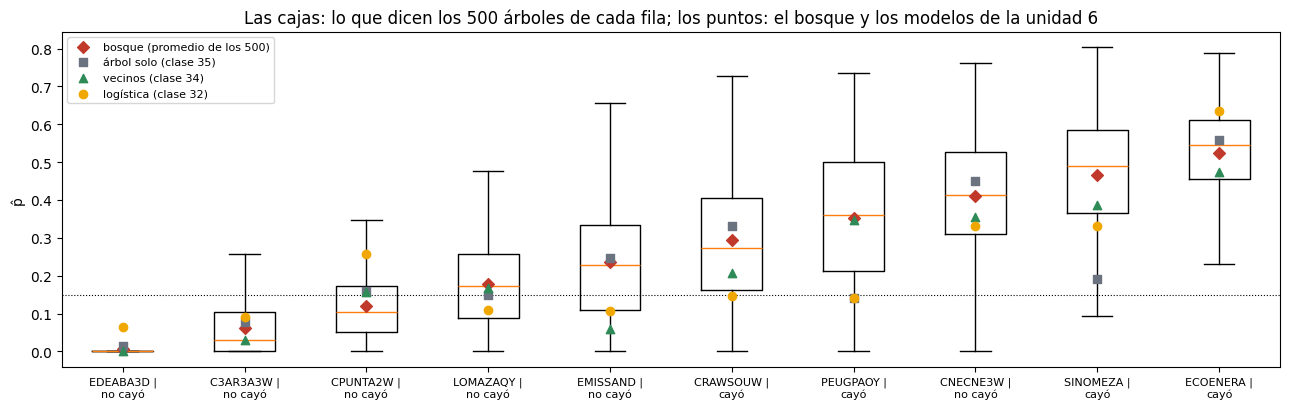

EDEABA3D | TARIFA USUARIO NO (no cayó): 1 de 500 árboles superan 0.15; p̂ del bosque 0.006, entre árboles de 0.00 a 0.02 (árbol solo 0.01, vecinos 0.00, logística 0.07).
C3AR3A3W | TARIFA USUARIO NO (no cayó): 80 de 500 árboles superan 0.15; p̂ del bosque 0.063, entre árboles de 0.00 a 0.19 (árbol solo 0.08, vecinos 0.03, logística 0.09).
CPUNTA2W | TARIFA BASE ELECT (no cayó): 156 de 500 árboles superan 0.15; p̂ del bosque 0.121, entre árboles de 0.02 a 0.25 (árbol solo 0.16, vecinos 0.16, logística 0.26).
LOMAZAQY | GUMAS/AUTOGENERAD (no cayó): 285 de 500 árboles superan 0.15; p̂ del bosque 0.179, entre árboles de 0.04 a 0.33 (árbol solo 0.15, vecinos 0.17, logística 0.11).
EMISSAND | TARIFA USUARIO NO (no cayó): 334 de 500 árboles superan 0.15; p̂ del bosque 0.237, entre árboles de 0.04 a 0.44 (árbol solo 0.25, vecinos 0.06, logística 0.11).
CRAWSOUW | TARIFA USUARIO NO (cayó): 385 de 500 árboles superan 0.15; p̂ del bosque 0.294, entre árboles de 0.09 a 0.53 (árbol solo 0.33, vecin

In [23]:
fig, ax = plt.subplots(figsize=(13, 4.2))
posiciones = np.arange(len(elegidos))
ax.boxplot([votos10[:, k] for k in range(len(elegidos))], positions=posiciones, widths=0.5, showfliers=False)
ax.scatter(posiciones, explicado["p̂ bosque"], color=ROJO, marker="D", zorder=5, label="bosque (promedio de los 500)")
ax.scatter(posiciones, explicado["p̂ árbol solo"], color=GRIS, marker="s", zorder=5, label="árbol solo (clase 35)")
ax.scatter(posiciones, explicado["p̂ vecinos"], color=VERDE, marker="^", zorder=5, label="vecinos (clase 34)")
ax.scatter(posiciones, explicado["p̂ logística"], color=AMBAR, marker="o", zorder=5, label="logística (clase 32)")
ax.set_xticks(posiciones); ax.set_xticklabels([f"{s[:10]}\n{'cayó' if r == 1 else 'no cayó'}" for s, r in zip(explicado["serie"], explicado["real"])], fontsize=8)
ax.axhline(UMBRAL_ALT, color="black", lw=0.8, ls=":"); ax.set_ylabel("p̂"); ax.legend(loc="upper left", fontsize=8)
ax.set_title("Las cajas: lo que dicen los 500 árboles de cada fila; los puntos: el bosque y los modelos de la unidad 6")
plt.tight_layout(); plt.show()
for fila_id, j, k in zip(explicado.index, elegidos, range(len(elegidos))):
    real = "cayó" if y_pru.iloc[j] == 1 else "no cayó"
    print(f"{explicado.loc[fila_id, 'serie']} ({real}): {explicado.loc[fila_id, f'árboles ≥ {UMBRAL_ALT}']} de 500 árboles superan {UMBRAL_ALT}; p̂ del bosque {prob_bosque[j]:.3f}, "
          f"entre árboles de {np.percentile(votos10[:, k], 10):.2f} a {np.percentile(votos10[:, k], 90):.2f} (árbol solo {explicado.loc[fila_id, 'p̂ árbol solo']:.2f}, vecinos {explicado.loc[fila_id, 'p̂ vecinos']:.2f}, logística {explicado.loc[fila_id, 'p̂ logística']:.2f}).")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La misma predicción, en una aplicación</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Se guarda el bosque elegido con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">joblib</code> comprimido (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">compress=3</code>): guarda cada nodo de sus 500 árboles. La app lo carga junto con los modelos de las clases 32, 34 y 35 que estén en la carpeta, y muestra las cinco probabilidades; la explicación del bosque es el reparto de lo que dicen sus árboles.</p></div>

In [24]:
import joblib

joblib.dump(bosque, "modelo_cammesa_38_bosque.joblib", compress=3)
cargado = joblib.load("modelo_cammesa_38_bosque.joblib")
print(f"modelo_cammesa_38_bosque.joblib · mismas probabilidades tras guardar y cargar: {np.allclose(cargado.predict_proba(X_pru), bosque.predict_proba(X_pru))}"
      f" · {Path('modelo_cammesa_38_bosque.joblib').stat().st_size / 1024 / 1024:,.1f} MB comprimido")

modelo_cammesa_38_bosque.joblib · mismas probabilidades tras guardar y cargar: True · 12.1 MB comprimido


In [25]:
%%writefile app_cammesa_38.py
# Clase 38 sobre CAMMESA · bosque aleatorio, contra los modelos de la unidad 6 · aplicación Streamlit
# Para abrirla, desde la carpeta del cuaderno:  streamlit run app_cammesa_38.py
import calendar
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

PREDICTORAS = ["ratio_dias", "var_mes_ant", "volatilidad", "var_hace_un_anio", "log_tamano", "mes_num", "es_gran_usuario", "es_residencial"]
AZUL, ROJO = "#0055a5", "#c0392b"
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]

st.set_page_config(page_title="¿Va a caer fuerte la demanda?", layout="centered")
st.title("¿La demanda de este agente va a caer fuerte?")
st.caption("Logística (clase 32), k vecinos y Bayes ingenuo (clase 34), árbol (clase 35) y bosque aleatorio (clase 38), sobre demanda-ltimos-aos.csv (CAMMESA).")

# ---------- 1 · Los modelos guardados por los cuadernos ----------
MODELOS = {
    "regresión logística": ("modelo_cammesa_32.joblib", "Clase_32_regresion_logistica_y_softmax_CAMMESA.ipynb"),
    "k vecinos": ("modelo_cammesa_34_knn.joblib", "Clase_34_k_vecinos_y_Bayes_ingenuo_CAMMESA.ipynb"),
    "Bayes ingenuo": ("modelo_cammesa_34_bayes.joblib", "Clase_34_k_vecinos_y_Bayes_ingenuo_CAMMESA.ipynb"),
    "árbol de decisión": ("modelo_cammesa_35.joblib", "Clase_35_arboles_de_decision_CAMMESA.ipynb"),
    "bosque aleatorio": ("modelo_cammesa_38_bosque.joblib", "Clase_38_ensambles_por_promediado_CAMMESA.ipynb"),
}
PROPIOS = ["bosque aleatorio"]

@st.cache_resource
def cargar(archivo):
    return joblib.load(archivo)

modelos = {}
for nombre, (archivo, cuaderno) in MODELOS.items():
    if Path(archivo).exists():
        modelos[nombre] = cargar(archivo)
    elif nombre in PROPIOS:
        st.error(f"Falta {archivo}. Ejecutar antes el cuaderno {cuaderno}, que lo genera."); st.stop()
    else:
        st.warning(f"Falta {archivo} (lo genera {cuaderno}): la comparación se muestra sin {nombre}.")
config = json.loads(Path("umbral_cammesa_32.json").read_text(encoding="utf-8")) if Path("umbral_cammesa_32.json").exists() else {"umbral": 0.15}

# ---------- 2 · La historia del agente ----------
st.subheader("Historia del agente")
c1, c2 = st.columns(2)
lag1 = c1.number_input("Demanda del mes anterior (MWh)", 1.0, 1_600_000.0, 5_000.0, step=100.0)
lag2 = c1.number_input("Demanda de hace dos meses (MWh)", 0.0, 1_600_000.0, 4_800.0, step=100.0)
conoce_anio = c1.checkbox("Conozco el año pasado", value=True)
lag12 = c1.number_input("Hace un año: el mismo mes (MWh)", 0.0, 1_600_000.0, 5_200.0, step=100.0, disabled=not conoce_anio)
lag13 = c1.number_input("Hace un año: el mes anterior (MWh)", 0.0, 1_600_000.0, 5_000.0, step=100.0, disabled=not conoce_anio)
anio = c2.number_input("Año", 2017, 2030, 2020)
mes = MESES.index(c2.selectbox("Mes a predecir", MESES, index=1)) + 1
tipo = c2.radio("Tipo de agente", ["Distribuidor · residencial", "Distribuidor · no residencial", "Gran usuario"])
umbral = c2.slider("Umbral de decisión", 0.05, 0.60, float(config["umbral"]), step=0.01)

anio_ant, mes_ant = (anio - 1, 12) if mes == 1 else (anio, mes - 1)
var_mes_ant = float(np.clip(lag1 / lag2 - 1, -1, 3)) if lag2 > 0 else np.nan
var_anio = float(np.clip(lag12 / lag13 - 1, -1, 3)) if conoce_anio and lag13 > 0 else np.nan
fila = pd.DataFrame([{"ratio_dias": calendar.monthrange(anio, mes)[1] / calendar.monthrange(anio_ant, mes_ant)[1],
                      "var_mes_ant": var_mes_ant, "volatilidad": abs(var_mes_ant) if not np.isnan(var_mes_ant) else np.nan,
                      "var_hace_un_anio": var_anio, "log_tamano": np.log10(lag1), "mes_num": mes,
                      "es_gran_usuario": int(tipo == "Gran usuario"), "es_residencial": int(tipo == "Distribuidor · residencial")}])[PREDICTORAS]

# ---------- 3 · Probabilidad y decisión de cada modelo ----------
probs = {nombre: float(m.predict_proba(fila)[0, 1]) for nombre, m in modelos.items()}
st.subheader("Predicción")
fig, ax = plt.subplots(figsize=(8, 0.6 + 0.55 * len(probs)))
ax.barh(list(probs), list(probs.values()), color=[ROJO if p >= umbral else AZUL for p in probs.values()])
ax.axvline(umbral, color="black", ls="--", lw=1.5, label=f"umbral = {umbral:.2f}")
for k, p in enumerate(probs.values()): ax.text(min(p + 0.01, 0.9), k, f"{p:.3f}", va="center")
ax.set_xlim(0, 1); ax.set_xlabel("p̂(cae fuerte)"); ax.invert_yaxis(); ax.legend(loc="lower right")
plt.tight_layout(); st.pyplot(fig)
p_b = probs["bosque aleatorio"]
st.markdown(f"**Bosque:** {p_b * 100:.1f} % → :{'red' if p_b >= umbral else 'blue'}[**{'alarma: puede caer fuerte' if p_b >= umbral else 'sin alarma'}**]".replace(".", ",", 1))

# ---------- 4 · Por qué ----------
st.subheader("Por qué")
pestanas = dict(zip(modelos, st.tabs(list(modelos))))
with pestanas["bosque aleatorio"]:
    bosque = modelos["bosque aleatorio"]
    votos = np.array([a.predict_proba(fila.to_numpy())[0, 1] for a in bosque.estimators_])
    st.write(f"El bosque promedia lo que dicen sus **{len(votos)}** árboles: **{(votos >= umbral).sum()}** de ellos le dan una probabilidad mayor o igual al umbral. "
             f"El 80 % central va de {np.percentile(votos, 10):.2f} a {np.percentile(votos, 90):.2f}.")
    fig, ax = plt.subplots(figsize=(8, 3)); ax.hist(votos, bins=40, color=ROJO, alpha=0.7)
    ax.axvline(votos.mean(), color="black", lw=2, label=f"promedio = {votos.mean():.3f}"); ax.axvline(umbral, color="black", ls="--", lw=1, label="umbral")
    ax.set_xlabel("p̂ de cada árbol"); ax.set_ylabel("árboles"); ax.legend(); plt.tight_layout(); st.pyplot(fig)
if "árbol de decisión" in modelos:
    with pestanas["árbol de decisión"]:
        arbol = modelos["árbol de decisión"]; t = arbol.tree_; nodos = arbol.decision_path(fila).indices
        for nodo in nodos[:-1]:
            j = t.feature[nodo]; col, u, v = PREDICTORAS[j], t.threshold[nodo], fila.iloc[0, j]
            st.write(f"• **{col}** falta → {'≤' if t.missing_go_to_left[nodo] else '>'} {u:.3g}" if pd.isna(v) else f"• **{col}** = {v:.3g} {'≤' if v <= u else '>'} {u:.3g}")
        hoja = nodos[-1]; cuentas = (t.value[hoja][0] * t.weighted_n_node_samples[hoja]).round().astype(int)
        st.write(f"→ de las {cuentas.sum()} filas de entrenamiento de esa hoja, **{cuentas[1]}** cayeron.")
if "k vecinos" in modelos:
    with pestanas["k vecinos"]:
        m = modelos["k vecinos"]; knn = m[-1]; dist, pos = knn.kneighbors(m[:-1].transform(fila)); votos_k = knn._y[pos[0]]
        st.write(f"De sus **{knn.n_neighbors}** vecinos más parecidos, **{int(votos_k.sum())}** cayeron fuerte.")
for nombre in ["Bayes ingenuo", "regresión logística"]:
    if nombre in modelos:
        with pestanas[nombre]:
            m = modelos[nombre]; x = m[:-1].transform(fila)[0]; final = m[-1]
            if nombre == "Bayes ingenuo":
                def logpdf(v, mu, var): return -0.5 * np.log(2 * np.pi * var) - (v - mu) ** 2 / (2 * var)
                aportes = logpdf(x, final.theta_[1], final.var_[1]) - logpdf(x, final.theta_[0], final.var_[0])
            else:
                aportes = final.coef_[0] * x
            fig, ax = plt.subplots(figsize=(8, 3.4)); ax.barh(PREDICTORAS, aportes, color=[ROJO if v > 0 else AZUL for v in aportes]); ax.axvline(0, color="black", lw=0.8); ax.invert_yaxis()
            ax.set_xlabel("aporte a las log-chances (rojo: hacia la caída)"); plt.tight_layout(); st.pyplot(fig)

with st.expander("Ver la fila que reciben los modelos"):
    st.dataframe(fila)

Overwriting app_cammesa_38.py


<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Cómo abrirla</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">streamlit</code> en <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">aa2026</code>: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">streamlit run app_cammesa_38.py</code> desde la carpeta del cuaderno. Para la comparación completa, correr antes los cuadernos 32, 34 y 35 en la misma carpeta; si falta alguno, la app avisa y sigue. Si otra app sigue abierta, esta arranca en <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">localhost:8502</code>.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Desde el cuaderno:</b> la celda siguiente la lanza sin consola; entrar a <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">http://localhost:8501</code> y, para cortarla, interrumpir el kernel (■).</p></div>

In [27]:
import sys
print("Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).")
!"{sys.executable}" -m streamlit run app_cammesa_38.py --server.headless true

Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).


^C


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">G · Qué quedó</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Muchos modelos flojos, votando, aciertan más</b> si se equivocan en lugares distintos. Con este desbalance, mirarlo pide un umbral bajo: con 0,5 los tres modelos de la unidad 6 dicen siempre «no cae». La votación blanda mejora a dos de los tres; tres árboles iguales no suman nada.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Remuestrear</b> da diversidad con el mismo algoritmo: un árbol de cien filas solo no sirve, quinientos promediados igualan a los vecinos, y con bolsas chicas mejor que con todas las filas. La bolsa estabiliza: cambia menos decisiones que un árbol frenado.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Lo que queda fuera de la bolsa</b> se cumple en la cuenta (37 %), pero con datos ordenados en el tiempo no estima lo mismo que la prueba: para elegir se usó la validación temporal.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>El bosque gana la unidad,</b> por encima de los vecinos en AUC y en log-loss, pero con un matiz respecto de la cátedra: con un objetivo ruidoso, un mínimo por hoja moderado (elegido en validación) le gana al bosque sin freno y lo hace mucho más liviano.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Las importancias:</b> la de impureza le da peso al ruido, sobre todo con árboles sin freno; la de permutación sobre prueba no. Y la app compara los cinco modelos sobre la misma fila, con los votos de los árboles como explicación del bosque.</p></div>